In [1]:
import copy, os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as func
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
DATA_DIR = "./data"
QUESTION = 3
PICS_DIR = "./figures"
BATCH_SIZE = 256
NUM_WORKERS = 4
VAL_RATIO = 0.1
BASELINE_EPOCHS = 8
REWEIGHT_FINE_TUNE_EPOCHS = 4
DOMAIN_CLF_EPOCHS = 5
DANN_EPOCHS = 6
CYCLEGAN_EPOCHS = 12
BATCH_SIZE_GAN = 128
LR_BASE = 1e-3
LR_REWEIGHT = 2e-4
LR_DOMAIN = 1e-3
LR_DANN = 2e-4
LR_GAN = 2e-4

LAMBDA_DOMAIN = 0.2
MAX_WEIGHT_CLIP = 3.0

LAMBDA_CYCLE = 10.0
LAMBDA_IDENTITY = 5.0

UPPER_BOUND_FINE_TUNE_EPOCHS = 8
LR_UPPER_BOUND = 5e-4

# Transforms

In [5]:
mean, std = 0.1307, 0.3081

# For classification models: baseline / reweighting / DANN
transform_cls = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])

# For GAN-based domain translation
transform_gan = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Dataset wrappers

In [ ]:
"""
Wrap an existing dataset to apply a transform to each image while preserving labels for use in training pipelines.
"""
class TensorMNISTDataset(Dataset):
    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, y = self.base_dataset[idx]
        x = self.transform(img)
        return x, y

In [ ]:
"""
Create a dataset that applies a fixed rotation to each image before transformation while keeping original labels.
"""
class RotatedMNISTDataset(Dataset):
    def __init__(self, base_dataset, angle_deg, transform):
        self.base_dataset = base_dataset
        self.angle_deg = angle_deg
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, y = self.base_dataset[idx]
        img = TF.rotate(img, angle=self.angle_deg, fill=0)
        x = self.transform(img)
        return x, y

# Datasets / Loaders

In [8]:
# Apply transforms through wrappers
train_base = datasets.MNIST(
    root=DATA_DIR, train=True, download=False, transform=None
)
test_base = datasets.MNIST(
    root=DATA_DIR, train=False, download=False, transform=None
)

# Train / Validation split
n_train = len(train_base)
indices = np.arange(n_train)

rng = np.random.default_rng(42)
rng.shuffle(indices)

n_val = int(VAL_RATIO * n_train)
val_indices = indices[:n_val]
train_indices = indices[n_val:]

# Classification datasets
source_train_full = TensorMNISTDataset(train_base, transform=transform_cls)
source_test = TensorMNISTDataset(test_base, transform=transform_cls)

source_train = Subset(source_train_full, train_indices)
source_val = Subset(source_train_full, val_indices)

target15_test = RotatedMNISTDataset(test_base, angle_deg=-15, transform=transform_cls)
target90_test = RotatedMNISTDataset(test_base, angle_deg=-90, transform=transform_cls)

# Target train datasets for upper bound
target15_train_full = RotatedMNISTDataset(train_base, angle_deg=-15, transform=transform_cls)
target90_train_full = RotatedMNISTDataset(train_base, angle_deg=-90, transform=transform_cls)

target15_train = Subset(target15_train_full, train_indices)
target15_val = Subset(target15_train_full, val_indices)

target90_train = Subset(target90_train_full, train_indices)
target90_val = Subset(target90_train_full, val_indices)

# GAN datasets
source_train_gan_full = TensorMNISTDataset(train_base, transform=transform_gan)
source_train_gan = Subset(source_train_gan_full, train_indices)

source_test_gan = TensorMNISTDataset(test_base, transform=transform_gan)
target15_test_gan = RotatedMNISTDataset(test_base, angle_deg=-15, transform=transform_gan)
target90_test_gan = RotatedMNISTDataset(test_base, angle_deg=-90, transform=transform_gan)
# Loaders - classification
source_train_loader = DataLoader(
    source_train, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)

source_val_loader = DataLoader(
    source_val, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

source_test_loader = DataLoader(
    source_test, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

target15_test_loader = DataLoader(
    target15_test, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

target90_test_loader = DataLoader(
    target90_test, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

# Target train datasets for upper bound
target15_train_loader = DataLoader(
    target15_train, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)

target15_val_loader = DataLoader(
    target15_val, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

target90_train_loader = DataLoader(
    target90_train, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)

target90_val_loader = DataLoader(
    target90_val, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

# Loaders - GAN
target15_test_loader_gan = DataLoader(
    target15_test_gan, batch_size=BATCH_SIZE_GAN, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

target90_test_loader_gan = DataLoader(
    target90_test_gan, batch_size=BATCH_SIZE_GAN, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

# LeNet

In [9]:
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = func.relu(self.conv1(x))
        x = func.max_pool2d(x, 2)
        x = func.relu(self.conv2(x))
        x = func.max_pool2d(x, 2)
        x = x.view(-1, 16 * 4 * 4)
        x = func.relu(self.fc1(x))
        x = func.relu(self.fc2(x))
        return self.fc3(x)

# Helper models for DANN / Reweighting

In [10]:
class LeNetEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)

    def forward(self, x):
        x = func.relu(self.conv1(x))
        x = func.max_pool2d(x, 2)
        x = func.relu(self.conv2(x))
        x = func.max_pool2d(x, 2)
        x = x.view(-1, 16 * 4 * 4)
        return x

In [11]:
class LeNetLabelClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, feat):
        x = func.relu(self.fc1(feat))
        x = func.relu(self.fc2(x))
        return self.fc3(x)

In [12]:
class DomainClassifier(nn.Module):
    def __init__(self, in_dim=16 * 4 * 4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, feat):
        return self.net(feat).squeeze(1)

# Utilities

In [13]:
def copy_lenet_to_dann(dann_model, lenet_model):
    """
    Copies trained LeNet weights into DANN encoder + label classifier.
    """
    dann_model.encoder.conv1.load_state_dict(lenet_model.conv1.state_dict())
    dann_model.encoder.conv2.load_state_dict(lenet_model.conv2.state_dict())

    dann_model.label_classifier.fc1.load_state_dict(lenet_model.fc1.state_dict())
    dann_model.label_classifier.fc2.load_state_dict(lenet_model.fc2.state_dict())
    dann_model.label_classifier.fc3.load_state_dict(lenet_model.fc3.state_dict())

In [14]:
def cycle_loader(loader):
    """
    Creates an infinite iterator over a dataloader.
    """
    while True:
        for batch in loader:
            yield batch

In [15]:
def plot_training_history(history, title="Training History"):
    epochs = np.arange(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(10, 4))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
    if "val_loss" in history:
        plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], marker="o", label="Train Acc")
    if "val_acc" in history:
        plt.plot(epochs, history["val_acc"], marker="o", label="Validation Acc")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [16]:
def plot_cyclegan_history(history, title="CycleGAN History"):
    """
    Plots CycleGAN generator and discriminator losses.
    """
    epochs = np.arange(1, len(history["G_loss"]) + 1)

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.plot(epochs, history["G_loss"], marker="o")
    plt.title(f"{title} - Generator")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 3, 2)
    plt.plot(epochs, history["D_S_loss"], marker="o")
    plt.title(f"{title} - D_S")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 3, 3)
    plt.plot(epochs, history["D_T_loss"], marker="o")
    plt.title(f"{title} - D_T")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [17]:
def plot_confusion_matrix_with_numbers(cm, title="Confusion Matrix", class_names=None, figsize=(8, 6)):
    """
    Plots confusion matrix and writes values inside each cell.
    """
    if class_names is None:
        class_names = [str(i) for i in range(cm.shape[0])]

    plt.figure(figsize=figsize)
    plt.imshow(cm, interpolation="nearest", cmap="Blues")
    plt.title(title)
    plt.colorbar()

    ticks = np.arange(len(class_names))
    plt.xticks(ticks, class_names)
    plt.yticks(ticks, class_names)

    thresh = cm.max() / 2.0 if cm.max() > 0 else 0.5
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=9
            )

    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()


In [18]:
def plot_per_class_accuracy(per_class_acc, title="Per-class Accuracy"):
    """
    Plots per-class accuracy.
    """
    classes = np.arange(len(per_class_acc))
    plt.figure(figsize=(8, 4))
    plt.bar(classes, per_class_acc)
    plt.xticks(classes, [str(c) for c in classes])
    plt.ylim(0, 1.0)
    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Accuracy")
    plt.grid(True, axis="y", alpha=0.3)
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [19]:
def plot_method_comparison(summary_df, domains=("Rot15", "Rot90")):
    """
    Plots method comparison for target domains.
    """
    for domain in domains:
        sub = summary_df[
            summary_df["EvaluationDomain"].str.startswith(domain)
        ].copy()

        plt.figure(figsize=(9, 4))
        plt.bar(sub["Method"], sub["Accuracy"])
        plt.ylim(0, 1.0)
        plt.title(f"Method Comparison on {domain}")
        plt.ylabel("Accuracy")
        plt.xticks(rotation=20, ha="right")
        plt.grid(True, axis="y", alpha=0.3)

        for i, v in enumerate(sub["Accuracy"].values):
            plt.text(i, v + 0.01, f"{v:.3f}", ha="center")

        plt.tight_layout()

        title = f"Method Comparison on {domain}"
        filename = f"{QUESTION}_{title}.png"
        save_path = os.path.join(PICS_DIR, filename)
        plt.savefig(save_path, dpi=300)
        plt.show()

In [ ]:
"""
Display a set of sample images from a dataset with proper denormalization for visualization and save the result.
"""
def show_samples(dataset, n=8, title="Samples"):
    """
    Shows sample images from a dataset.
    """
    plt.figure(figsize=(12, 2))
    for i in range(n):
        x, y = dataset[i]

        # undo normalization just for display
        img = x.clone().cpu()

        # classification normalized
        if img.min() < -0.2 and img.max() > 1.2:
            img = img * std + mean
        # GAN normalized [-1,1]
        elif img.min() < 0:
            img = img * 0.5 + 0.5

        img = torch.clamp(img, 0.0, 1.0)

        plt.subplot(1, n, i + 1)
        plt.imshow(img.squeeze(0), cmap="gray")
        plt.title(str(y))
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    title = f"{title} samples"
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [21]:
def make_result_rows(method_name, domain_name, eval_result):
    rows = []
    for c, a in enumerate(eval_result["per_class_acc"]):
        rows.append({
            "Method": method_name,
            "EvaluationDomain": domain_name,
            "Class": c,
            "PerClassAcc": float(a)
        })
    return rows

In [22]:
def class_improvement(before_eval, after_eval, method_name, domain_name):
    """
    Shows per-class improvement relative to baseline.
    """
    diff = after_eval["per_class_acc"] - before_eval["per_class_acc"]

    df = pd.DataFrame({
        "Class": list(range(10)),
        "Before": before_eval["per_class_acc"],
        "After": after_eval["per_class_acc"],
        "Improvement": diff
    }).sort_values("Improvement", ascending=False)

    print(f"\n=== Class Improvement | {method_name} | {domain_name} ===")
    display(df)

    plt.figure(figsize=(8, 4))
    plt.bar(df["Class"].astype(str), df["Improvement"])
    plt.title(f"Per-class Improvement - {method_name} on {domain_name}")
    plt.xlabel("Class")
    plt.ylabel("Accuracy Improvement")
    plt.grid(True, axis="y", alpha=0.3)
    title = f"Per-class Improvement - {method_name} on {domain_name}"
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

# Baseline train / eval

In [ ]:
"""
Train a classification model while tracking training metrics and optionally evaluating on a validation set across epochs.
"""
def train_classifier(model, train_loader, val_loader=None, epochs=5, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "train_acc": []
    }

    if val_loader is not None:
        history["val_loss"] = []
        history["val_acc"] = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            preds = logits.argmax(dim=1)

            total_loss += loss.item() * y.size(0)
            total_correct += (preds == y).sum().item()
            total_samples += y.size(0)

        epoch_train_loss = total_loss / total_samples
        epoch_train_acc = total_correct / total_samples

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)

        if val_loader is not None:
            model.eval()
            val_loss_sum = 0.0
            val_correct = 0
            val_samples = 0

            with torch.no_grad():
                for x, y in val_loader:
                    x, y = x.to(device), y.to(device)

                    logits = model(x)
                    loss = criterion(logits, y)
                    preds = logits.argmax(dim=1)

                    val_loss_sum += loss.item() * y.size(0)
                    val_correct += (preds == y).sum().item()
                    val_samples += y.size(0)

            epoch_val_loss = val_loss_sum / val_samples
            epoch_val_acc = val_correct / val_samples

            history["val_loss"].append(epoch_val_loss)
            history["val_acc"].append(epoch_val_acc)

            print(
                f"[Baseline] Epoch {epoch+1}/{epochs} | "
                f"train_loss={epoch_train_loss:.4f} | train_acc={epoch_train_acc:.4f} | "
                f"val_loss={epoch_val_loss:.4f} | val_acc={epoch_val_acc:.4f}"
            )
        else:
            print(
                f"[Baseline] Epoch {epoch+1}/{epochs} | "
                f"train_loss={epoch_train_loss:.4f} | train_acc={epoch_train_acc:.4f}"
            )

    return history

In [24]:
@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()

    y_true = []
    y_pred = []

    for x, y in loader:
        x = x.to(device)
        logits = model(x)
        preds = logits.argmax(dim=1).cpu().numpy()

        y_pred.extend(preds.tolist())
        y_true.extend(y.numpy().tolist())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acc = (y_true == y_pred).mean()
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    per_class_acc = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)

    return {
        "accuracy": acc,
        "y_true": y_true,
        "y_pred": y_pred,
        "cm": cm,
        "per_class_acc": per_class_acc
    }


================ BASELINE TRAINING ================

[Baseline] Epoch 1/8 | train_loss=0.5050 | train_acc=0.8525 | val_loss=0.1747 | val_acc=0.9487
[Baseline] Epoch 2/8 | train_loss=0.1277 | train_acc=0.9615 | val_loss=0.1198 | val_acc=0.9627
[Baseline] Epoch 3/8 | train_loss=0.0845 | train_acc=0.9738 | val_loss=0.0892 | val_acc=0.9715
[Baseline] Epoch 4/8 | train_loss=0.0661 | train_acc=0.9796 | val_loss=0.0648 | val_acc=0.9792
[Baseline] Epoch 5/8 | train_loss=0.0566 | train_acc=0.9823 | val_loss=0.0661 | val_acc=0.9798
[Baseline] Epoch 6/8 | train_loss=0.0490 | train_acc=0.9848 | val_loss=0.0644 | val_acc=0.9800
[Baseline] Epoch 7/8 | train_loss=0.0397 | train_acc=0.9881 | val_loss=0.0508 | val_acc=0.9842
[Baseline] Epoch 8/8 | train_loss=0.0365 | train_acc=0.9887 | val_loss=0.0473 | val_acc=0.9845


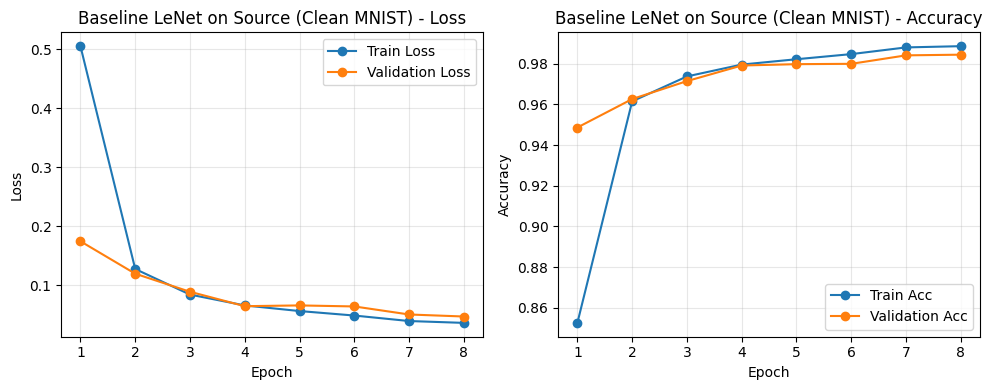


=== Baseline / No Adaptation ===
Clean Test Accuracy : 0.9862
Rot15 Test Accuracy : 0.9481
Rot90 Test Accuracy : 0.1692


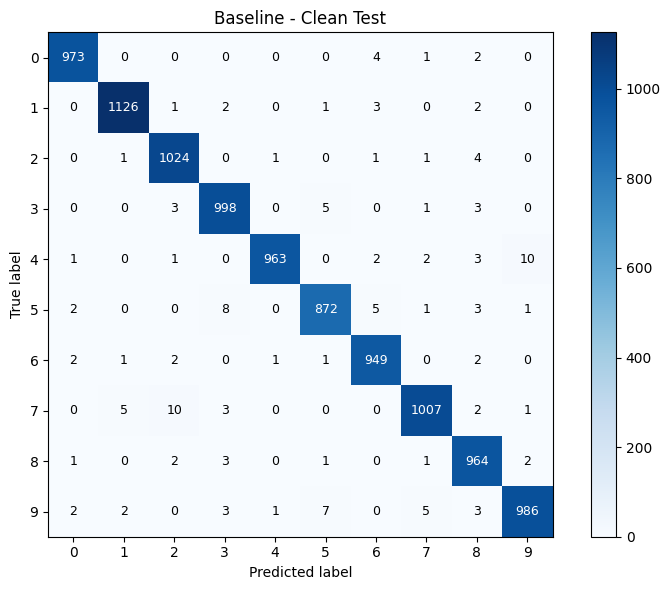

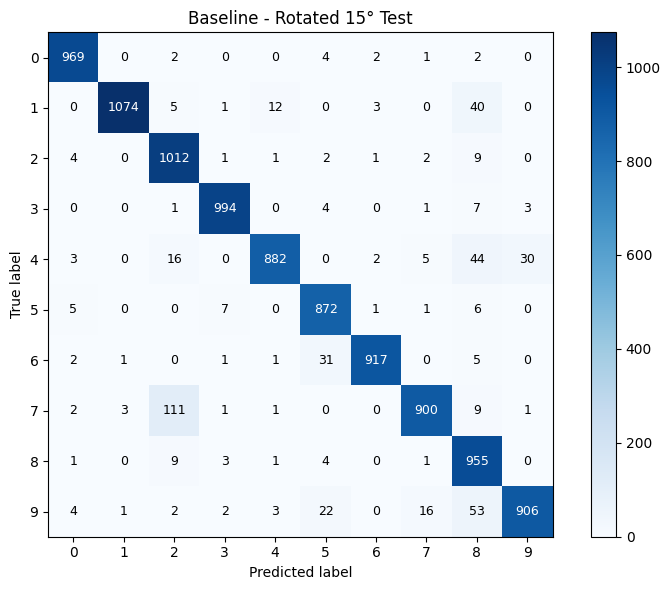

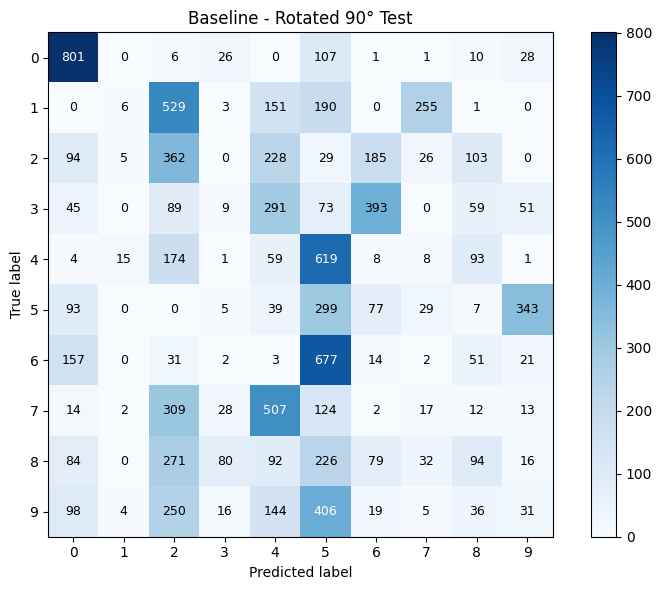

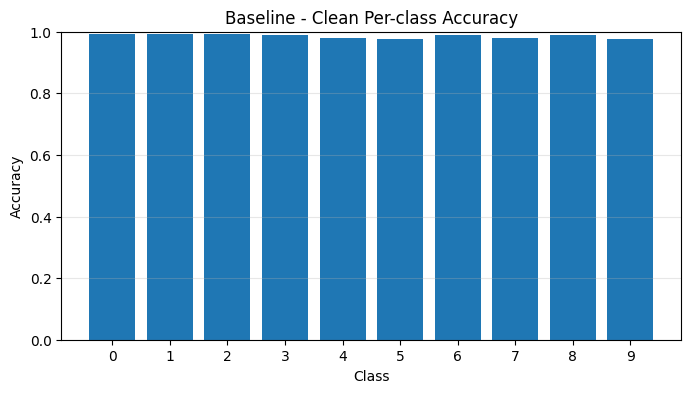

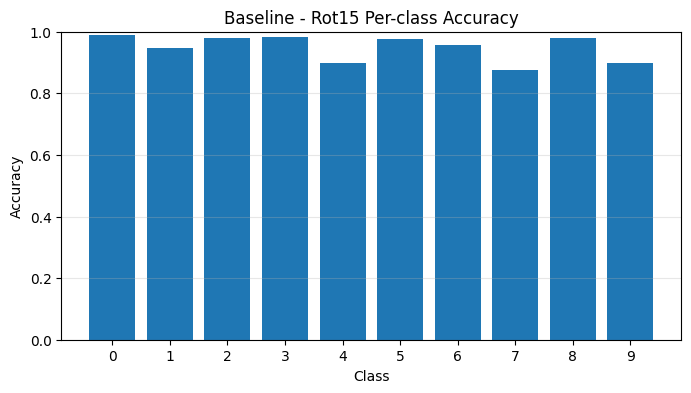

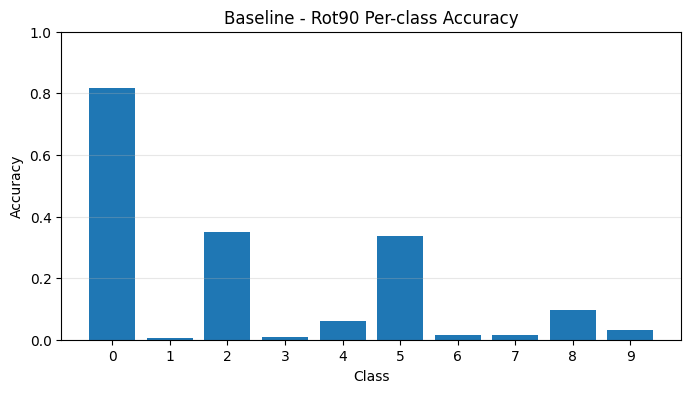

In [25]:
print("\n================ BASELINE TRAINING ================\n")
baseline_model = LeNet().to(device)
baseline_history = train_classifier(
    baseline_model,
    source_train_loader,
    val_loader=source_val_loader,
    epochs=BASELINE_EPOCHS,
    lr=LR_BASE
)

plot_training_history(baseline_history, title="Baseline LeNet on Source (Clean MNIST)")

baseline_clean = evaluate_model(baseline_model, source_test_loader)
baseline_rot15 = evaluate_model(baseline_model, target15_test_loader)
baseline_rot90 = evaluate_model(baseline_model, target90_test_loader)

print("\n=== Baseline / No Adaptation ===")
print(f"Clean Test Accuracy : {baseline_clean['accuracy']:.4f}")
print(f"Rot15 Test Accuracy : {baseline_rot15['accuracy']:.4f}")
print(f"Rot90 Test Accuracy : {baseline_rot90['accuracy']:.4f}")

plot_confusion_matrix_with_numbers(baseline_clean["cm"], title="Baseline - Clean Test")
plot_confusion_matrix_with_numbers(baseline_rot15["cm"], title="Baseline - Rotated 15° Test")
plot_confusion_matrix_with_numbers(baseline_rot90["cm"], title="Baseline - Rotated 90° Test")

plot_per_class_accuracy(baseline_clean["per_class_acc"], title="Baseline - Clean Per-class Accuracy")
plot_per_class_accuracy(baseline_rot15["per_class_acc"], title="Baseline - Rot15 Per-class Accuracy")
plot_per_class_accuracy(baseline_rot90["per_class_acc"], title="Baseline - Rot90 Per-class Accuracy")


# Supervised fine-tuning (upper bound)

In [ ]:
"""
Fine-tune a classifier on labeled target-domain data as an oracle upper-bound reference and track training and validation metrics.
"""

def fine_tune_on_labeled_target(model, train_loader, val_loader=None, epochs=5, lr=5e-4):
    """
    Supervised fine-tuning on labeled target-domain data.
    This is used only as an oracle / upper bound reference.
    """
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "train_acc": []
    }

    if val_loader is not None:
        history["val_loss"] = []
        history["val_acc"] = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            preds = logits.argmax(dim=1)

            total_loss += loss.item() * y.size(0)
            total_correct += (preds == y).sum().item()
            total_samples += y.size(0)

        epoch_train_loss = total_loss / total_samples
        epoch_train_acc = total_correct / total_samples

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)

        if val_loader is not None:
            model.eval()
            val_loss_sum = 0.0
            val_correct = 0
            val_samples = 0

            with torch.no_grad():
                for x, y in val_loader:
                    x, y = x.to(device), y.to(device)

                    logits = model(x)
                    loss = criterion(logits, y)
                    preds = logits.argmax(dim=1)

                    val_loss_sum += loss.item() * y.size(0)
                    val_correct += (preds == y).sum().item()
                    val_samples += y.size(0)

            epoch_val_loss = val_loss_sum / val_samples
            epoch_val_acc = val_correct / val_samples

            history["val_loss"].append(epoch_val_loss)
            history["val_acc"].append(epoch_val_acc)

            print(
                f"[Upper Bound] Epoch {epoch+1}/{epochs} | "
                f"train_loss={epoch_train_loss:.4f} | train_acc={epoch_train_acc:.4f} | "
                f"val_loss={epoch_val_loss:.4f} | val_acc={epoch_val_acc:.4f}"
            )
        else:
            print(
                f"[Upper Bound] Epoch {epoch+1}/{epochs} | "
                f"train_loss={epoch_train_loss:.4f} | train_acc={epoch_train_acc:.4f}"
            )

    return history

In [ ]:
"""
Train and evaluate a supervised target-domain upper-bound model, comparing its performance on clean and target-domain test sets.
"""

def run_supervised_target_upper_bound(train_loader, val_loader, test_loader, target_name="Rot15"):
    """
    Trains on labeled target-domain data.
    This is NOT a domain adaptation method.
    It is only an oracle / upper-bound reference.
    """
    print(f"\n================ Supervised Target Upper Bound on {target_name} ================")

    model = copy.deepcopy(baseline_model)

    history = fine_tune_on_labeled_target(
        model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=UPPER_BOUND_FINE_TUNE_EPOCHS,
        lr=LR_UPPER_BOUND
    )

    plot_training_history(history, title=f"Supervised Target Upper Bound - {target_name}")

    clean_eval = evaluate_model(model, source_test_loader)
    target_eval = evaluate_model(model, test_loader)

    print(f"\n[Upper Bound - {target_name}]")
    print(f"Clean Test Accuracy : {clean_eval['accuracy']:.4f}")
    print(f"{target_name} Test Accuracy : {target_eval['accuracy']:.4f}")

    return model, clean_eval, target_eval


================ Supervised Target Upper Bound on Rot15 ================
[Upper Bound] Epoch 1/8 | train_loss=0.0595 | train_acc=0.9807 | val_loss=0.0594 | val_acc=0.9815
[Upper Bound] Epoch 2/8 | train_loss=0.0422 | train_acc=0.9866 | val_loss=0.0517 | val_acc=0.9828
[Upper Bound] Epoch 3/8 | train_loss=0.0356 | train_acc=0.9887 | val_loss=0.0498 | val_acc=0.9848
[Upper Bound] Epoch 4/8 | train_loss=0.0305 | train_acc=0.9908 | val_loss=0.0514 | val_acc=0.9837
[Upper Bound] Epoch 5/8 | train_loss=0.0282 | train_acc=0.9913 | val_loss=0.0481 | val_acc=0.9852
[Upper Bound] Epoch 6/8 | train_loss=0.0246 | train_acc=0.9919 | val_loss=0.0511 | val_acc=0.9845
[Upper Bound] Epoch 7/8 | train_loss=0.0225 | train_acc=0.9931 | val_loss=0.0460 | val_acc=0.9862
[Upper Bound] Epoch 8/8 | train_loss=0.0195 | train_acc=0.9939 | val_loss=0.0531 | val_acc=0.9847


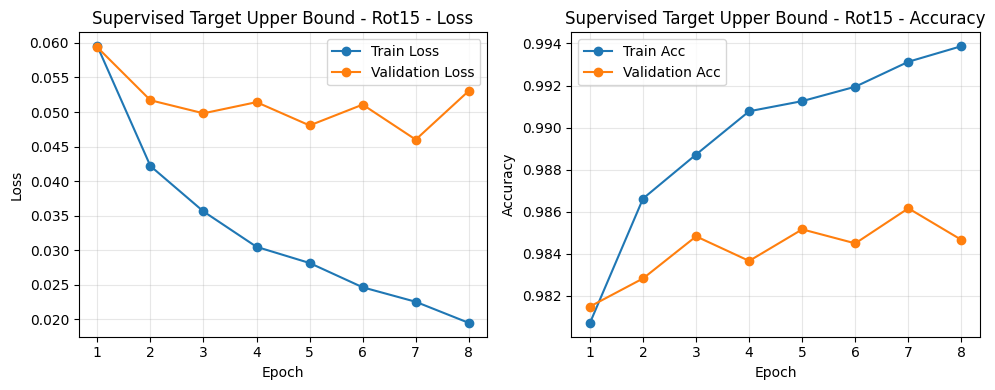


[Upper Bound - Rot15]
Clean Test Accuracy : 0.9737
Rot15 Test Accuracy : 0.9863

================ Supervised Target Upper Bound on Rot90 ================
[Upper Bound] Epoch 1/8 | train_loss=0.5402 | train_acc=0.8480 | val_loss=0.1554 | val_acc=0.9477
[Upper Bound] Epoch 2/8 | train_loss=0.1192 | train_acc=0.9629 | val_loss=0.1006 | val_acc=0.9712
[Upper Bound] Epoch 3/8 | train_loss=0.0838 | train_acc=0.9743 | val_loss=0.0822 | val_acc=0.9757
[Upper Bound] Epoch 4/8 | train_loss=0.0674 | train_acc=0.9791 | val_loss=0.0666 | val_acc=0.9800
[Upper Bound] Epoch 5/8 | train_loss=0.0556 | train_acc=0.9831 | val_loss=0.0548 | val_acc=0.9842
[Upper Bound] Epoch 6/8 | train_loss=0.0483 | train_acc=0.9849 | val_loss=0.0547 | val_acc=0.9840
[Upper Bound] Epoch 7/8 | train_loss=0.0421 | train_acc=0.9871 | val_loss=0.0455 | val_acc=0.9863
[Upper Bound] Epoch 8/8 | train_loss=0.0372 | train_acc=0.9884 | val_loss=0.0509 | val_acc=0.9837


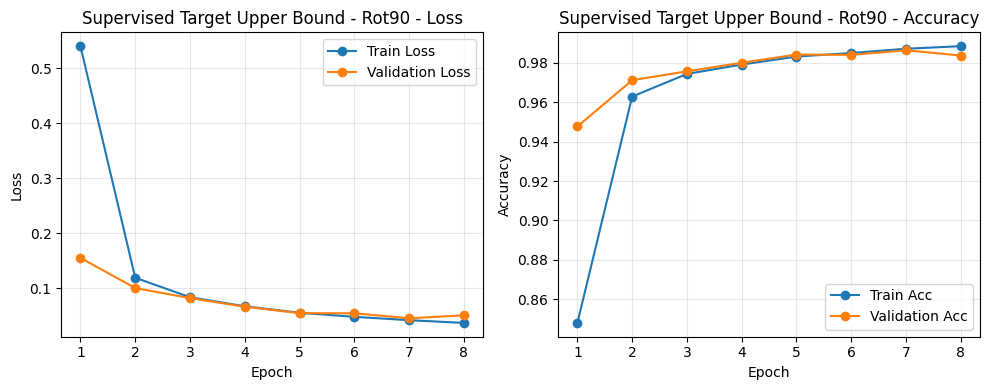


[Upper Bound - Rot90]
Clean Test Accuracy : 0.3326
Rot90 Test Accuracy : 0.9853


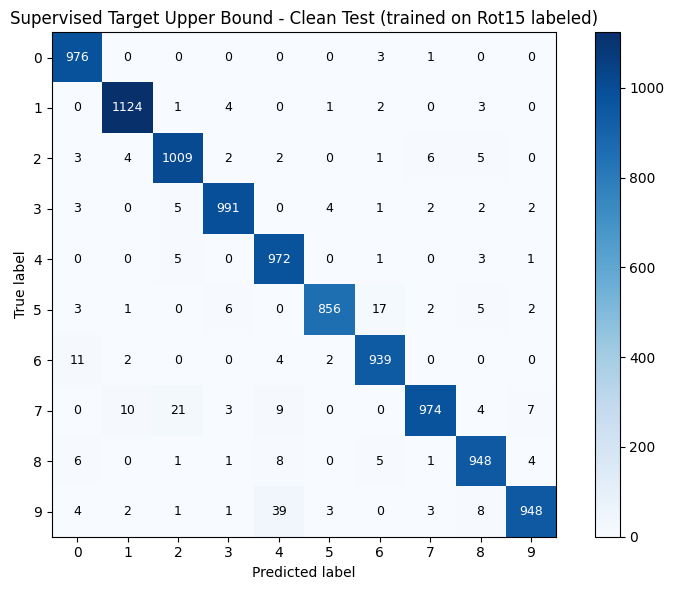

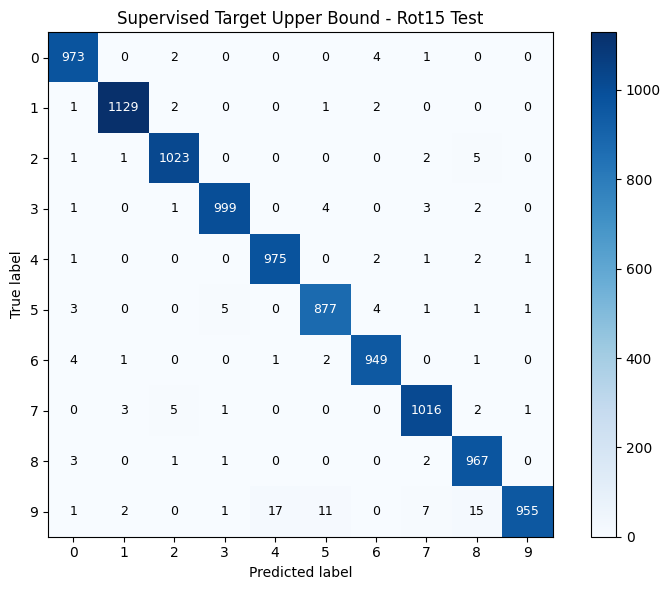

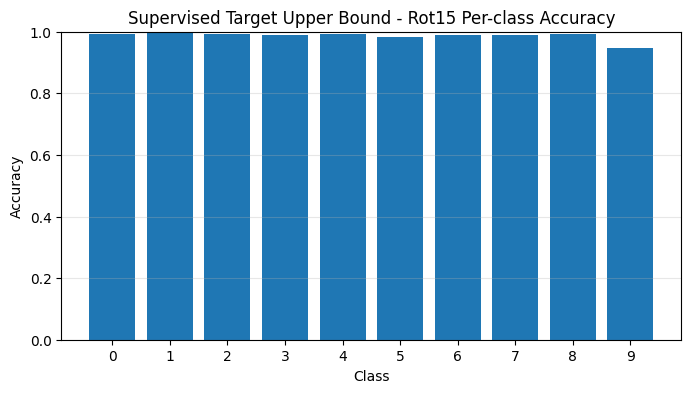

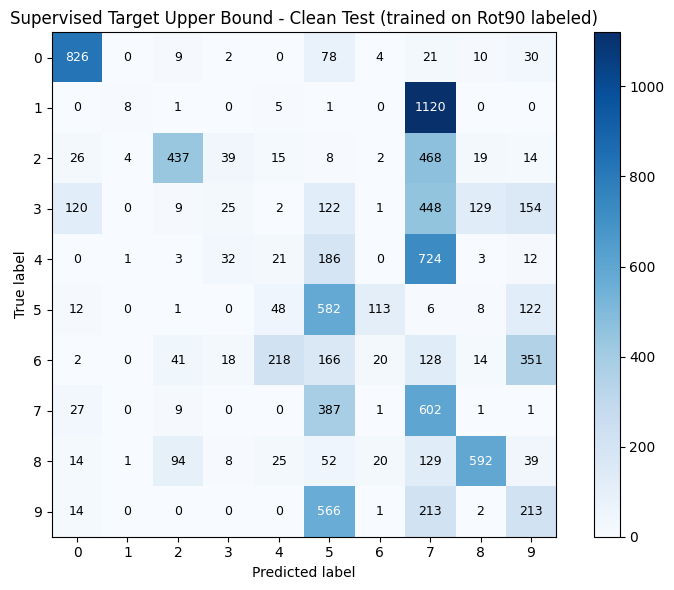

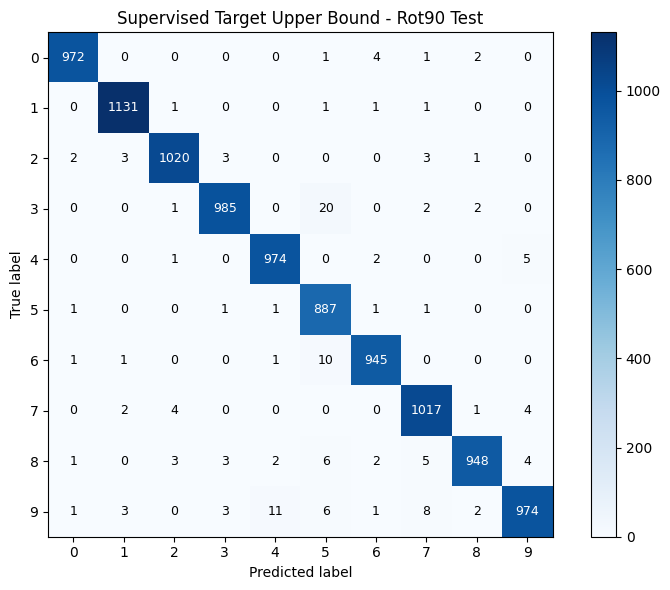

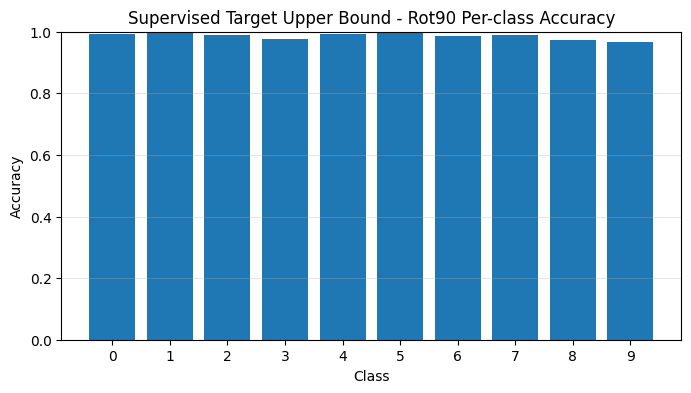

In [28]:
# ----------------------------
# Supervised Target Upper Bound
# ----------------------------
upper15_model, upper15_clean, upper15_target = run_supervised_target_upper_bound(
    train_loader=target15_train_loader,
    val_loader=target15_val_loader,
    test_loader=target15_test_loader,
    target_name="Rot15"
)

upper90_model, upper90_clean, upper90_target = run_supervised_target_upper_bound(
    train_loader=target90_train_loader,
    val_loader=target90_val_loader,
    test_loader=target90_test_loader,
    target_name="Rot90"
)

plot_confusion_matrix_with_numbers(
    upper15_clean["cm"],
    title="Supervised Target Upper Bound - Clean Test (trained on Rot15 labeled)"
)
plot_confusion_matrix_with_numbers(
    upper15_target["cm"],
    title="Supervised Target Upper Bound - Rot15 Test"
)
plot_per_class_accuracy(
    upper15_target["per_class_acc"],
    title="Supervised Target Upper Bound - Rot15 Per-class Accuracy"
)

plot_confusion_matrix_with_numbers(
    upper90_clean["cm"],
    title="Supervised Target Upper Bound - Clean Test (trained on Rot90 labeled)"
)
plot_confusion_matrix_with_numbers(
    upper90_target["cm"],
    title="Supervised Target Upper Bound - Rot90 Test"
)
plot_per_class_accuracy(
    upper90_target["per_class_acc"],
    title="Supervised Target Upper Bound - Rot90 Per-class Accuracy"
)

# Method 1: Reweighting / Importance Sampling

In [29]:
class SmallDomainCNN(nn.Module):
    """
    A small CNN to distinguish source vs target images.
    """
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x).squeeze(1)
        return x

In [30]:
class RawImageDomainDataset(Dataset):
    """
    Returns:
        source image -> domain label 1
        target image -> domain label 0
    """
    def __init__(self, source_dataset, target_dataset, source_indices=None):
        self.source_dataset = source_dataset
        self.target_dataset = target_dataset

        if source_indices is None:
            self.source_indices = list(range(len(source_dataset)))
        else:
            self.source_indices = list(source_indices)

        self.n_source = len(self.source_indices)
        self.n_target = len(target_dataset)

    def __len__(self):
        return self.n_source + self.n_target

    def __getitem__(self, idx):
        if idx < self.n_source:
            x, _ = self.source_dataset[self.source_indices[idx]]
            d = 1.0
        else:
            x, _ = self.target_dataset[idx - self.n_source]
            d = 0.0

        return x, torch.tensor(d, dtype=torch.float32)

In [ ]:
"""
Train a domain classifier to distinguish between domains using binary classification loss and report training loss per epoch.
"""
def train_domain_classifier(domain_model, loader, epochs=3, lr=1e-3):
    domain_model = domain_model.to(device)
    optimizer = torch.optim.Adam(domain_model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(epochs):
        domain_model.train()
        total_loss = 0.0
        total_samples = 0

        for x, d in loader:
            x, d = x.to(device), d.to(device)

            optimizer.zero_grad()
            logits = domain_model(x)
            loss = criterion(logits, d)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)
            total_samples += x.size(0)

        print(f"[Domain Clf] Epoch {epoch+1}/{epochs} | loss={total_loss / total_samples:.4f}")

In [32]:
@torch.no_grad()
def estimate_source_weights(domain_model, source_dataset, batch_size=256, clip_max=5.0):
    """
    weight(x) = p_t(x) / p_s(x) ~= (1 - c(source|x)) / c(source|x)
    """
    domain_model.eval()
    loader = DataLoader(source_dataset, batch_size=batch_size, shuffle=False)

    all_weights = []

    for x, _ in loader:
        x = x.to(device)
        logits = domain_model(x)
        c_source = torch.sigmoid(logits).clamp(1e-4, 1 - 1e-4)
        w = ((1.0 - c_source) / c_source).clamp(0.0, clip_max)
        all_weights.extend(w.cpu().numpy().tolist())

    return np.array(all_weights, dtype=np.float32)

In [33]:
class WeightedSourceDataset(Dataset):
    """
    Returns source samples with estimated importance weight.
    """
    def __init__(self, source_dataset, weights):
        self.source_dataset = source_dataset
        self.weights = weights.astype(np.float32)

    def __len__(self):
        return len(self.source_dataset)

    def __getitem__(self, idx):
        x, y = self.source_dataset[idx]
        w = self.weights[idx]
        return x, y, torch.tensor(w, dtype=torch.float32)

In [ ]:
"""
Fine-tune a classifier with sample-weighted loss to emphasize more relevant training examples and track training and validation metrics.
"""

def fine_tune_with_weights(model, weighted_loader, val_loader=None, epochs=3, lr=5e-4):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "train_acc": []
    }

    if val_loader is not None:
        history["val_loss"] = []
        history["val_acc"] = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for x, y, w in weighted_loader:
            x, y, w = x.to(device), y.to(device), w.to(device)

            optimizer.zero_grad()
            logits = model(x)
            per_sample_loss = func.cross_entropy(logits, y, reduction="none")
            loss = (per_sample_loss * w).mean()
            loss.backward()
            optimizer.step()

            preds = logits.argmax(dim=1)

            total_loss += loss.item() * y.size(0)
            total_correct += (preds == y).sum().item()
            total_samples += y.size(0)

        epoch_train_loss = total_loss / total_samples
        epoch_train_acc = total_correct / total_samples

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)

        if val_loader is not None:
            model.eval()
            val_loss_sum = 0.0
            val_correct = 0
            val_samples = 0

            with torch.no_grad():
                for x, y in val_loader:
                    x, y = x.to(device), y.to(device)

                    logits = model(x)
                    loss = func.cross_entropy(logits, y)
                    preds = logits.argmax(dim=1)

                    val_loss_sum += loss.item() * y.size(0)
                    val_correct += (preds == y).sum().item()
                    val_samples += y.size(0)

            epoch_val_loss = val_loss_sum / val_samples
            epoch_val_acc = val_correct / val_samples

            history["val_loss"].append(epoch_val_loss)
            history["val_acc"].append(epoch_val_acc)

            print(
                f"[Reweight FT] Epoch {epoch+1}/{epochs} | "
                f"train_loss={epoch_train_loss:.4f} | train_acc={epoch_train_acc:.4f} | "
                f"val_loss={epoch_val_loss:.4f} | val_acc={epoch_val_acc:.4f}"
            )
        else:
            print(
                f"[Reweight FT] Epoch {epoch+1}/{epochs} | "
                f"train_loss={epoch_train_loss:.4f} | train_acc={epoch_train_acc:.4f}"
            )

    return history

In [35]:
def run_reweighting_adaptation(target_dataset, target_loader, target_name="Rot15"):
    print(f"\n================ Reweighting Adaptation on {target_name} ================")

    n_target = len(target_dataset)
    source_indices = np.random.choice(len(source_train), size=n_target, replace=False)

    domain_ds = RawImageDomainDataset(
        source_dataset=source_train,
        target_dataset=target_dataset,
        source_indices=source_indices
    )

    domain_loader = DataLoader(
        domain_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    domain_model = SmallDomainCNN().to(device)
    train_domain_classifier(domain_model, domain_loader, epochs=DOMAIN_CLF_EPOCHS, lr=LR_DOMAIN)

    weights = estimate_source_weights(
        domain_model, source_train, batch_size=256, clip_max=MAX_WEIGHT_CLIP
    )

    print(f"Weight stats -> min={weights.min():.4f}, max={weights.max():.4f}, mean={weights.mean():.4f}")

    weighted_source = WeightedSourceDataset(source_train, weights)
    weighted_loader = DataLoader(
        weighted_source,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    model = copy.deepcopy(baseline_model)
    history = fine_tune_with_weights(
        model,
        weighted_loader,
        val_loader=source_val_loader,
        epochs=REWEIGHT_FINE_TUNE_EPOCHS,
        lr=LR_REWEIGHT
    )

    plot_training_history(history, title=f"Reweighting Fine-tune - {target_name}")

    clean_eval = evaluate_model(model, source_test_loader)
    target_eval = evaluate_model(model, target_loader)

    print(f"\n[Reweighting - {target_name}]")
    print(f"Clean Test Accuracy : {clean_eval['accuracy']:.4f}")
    print(f"{target_name} Test Accuracy : {target_eval['accuracy']:.4f}")
    
    return model, clean_eval, target_eval


================ Reweighting Adaptation on Rot15 ================


[Domain Clf] Epoch 1/5 | loss=0.4237
[Domain Clf] Epoch 2/5 | loss=0.1226
[Domain Clf] Epoch 3/5 | loss=0.0488
[Domain Clf] Epoch 4/5 | loss=0.0250
[Domain Clf] Epoch 5/5 | loss=0.0175
Weight stats -> min=0.0001, max=3.0000, mean=0.0161
[Reweight FT] Epoch 1/4 | train_loss=0.0011 | train_acc=0.9902 | val_loss=0.0578 | val_acc=0.9843
[Reweight FT] Epoch 2/4 | train_loss=0.0005 | train_acc=0.9917 | val_loss=0.0502 | val_acc=0.9855
[Reweight FT] Epoch 3/4 | train_loss=0.0004 | train_acc=0.9914 | val_loss=0.0508 | val_acc=0.9850
[Reweight FT] Epoch 4/4 | train_loss=0.0003 | train_acc=0.9919 | val_loss=0.0562 | val_acc=0.9845


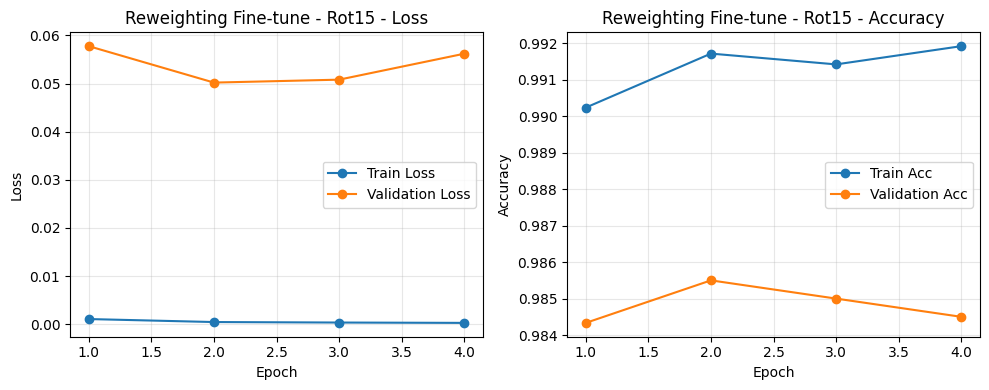


[Reweighting - Rot15]
Clean Test Accuracy : 0.9856
Rot15 Test Accuracy : 0.9550

================ Reweighting Adaptation on Rot90 ================
[Domain Clf] Epoch 1/5 | loss=0.1398
[Domain Clf] Epoch 2/5 | loss=0.0256
[Domain Clf] Epoch 3/5 | loss=0.0175
[Domain Clf] Epoch 4/5 | loss=0.0136
[Domain Clf] Epoch 5/5 | loss=0.0074
Weight stats -> min=0.0001, max=3.0000, mean=0.0575
[Reweight FT] Epoch 1/4 | train_loss=0.0033 | train_acc=0.9903 | val_loss=0.0563 | val_acc=0.9815
[Reweight FT] Epoch 2/4 | train_loss=0.0014 | train_acc=0.9911 | val_loss=0.0558 | val_acc=0.9838
[Reweight FT] Epoch 3/4 | train_loss=0.0009 | train_acc=0.9904 | val_loss=0.0504 | val_acc=0.9850
[Reweight FT] Epoch 4/4 | train_loss=0.0007 | train_acc=0.9912 | val_loss=0.0529 | val_acc=0.9845


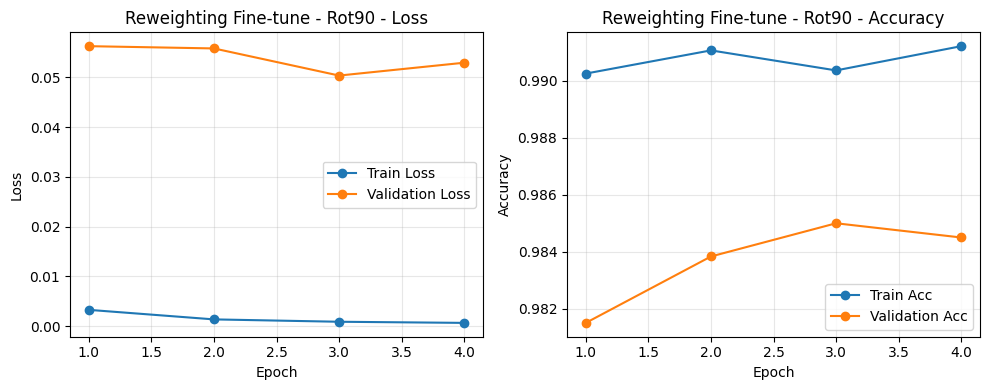


[Reweighting - Rot90]
Clean Test Accuracy : 0.9849
Rot90 Test Accuracy : 0.1691


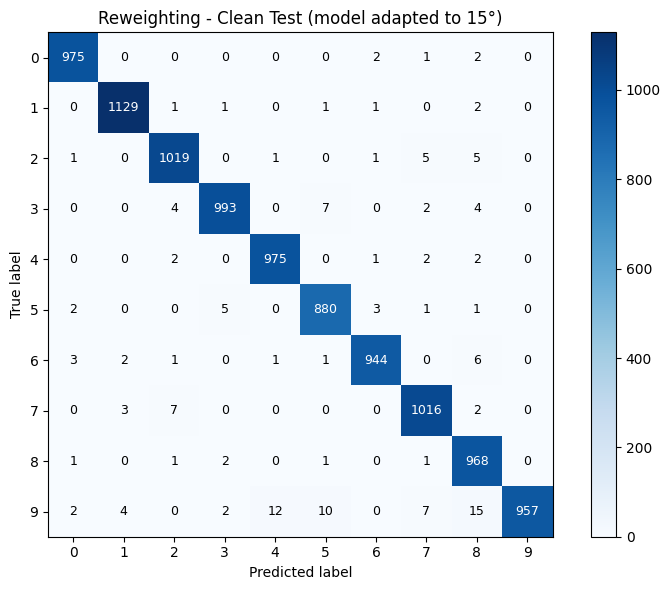

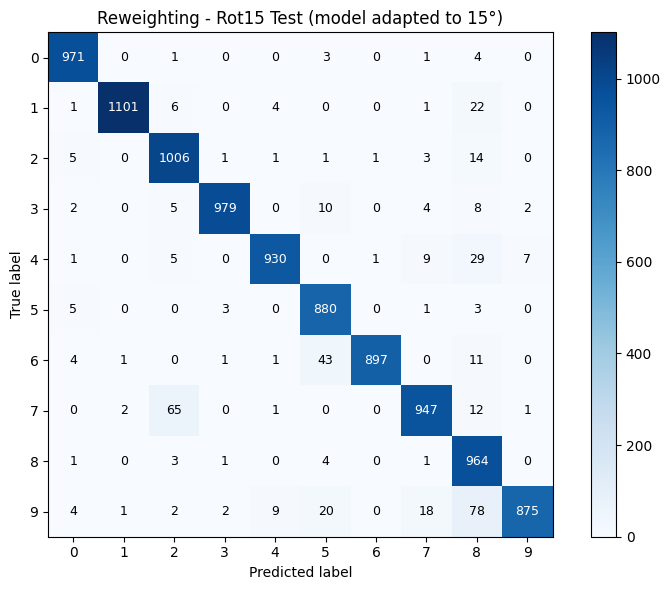

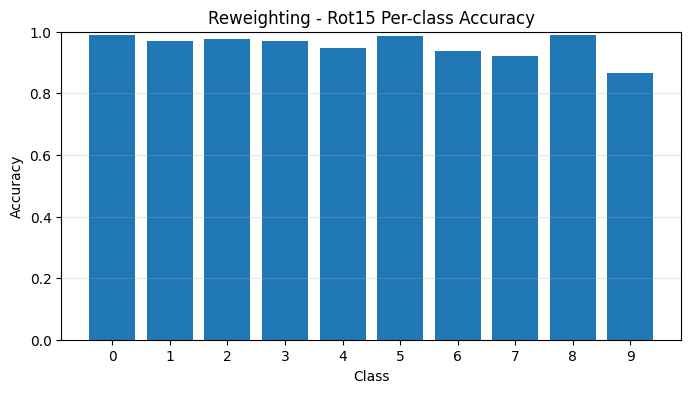

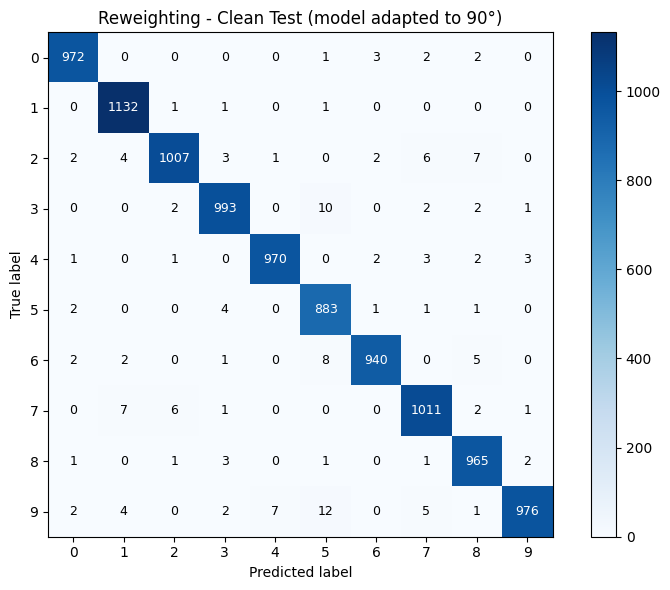

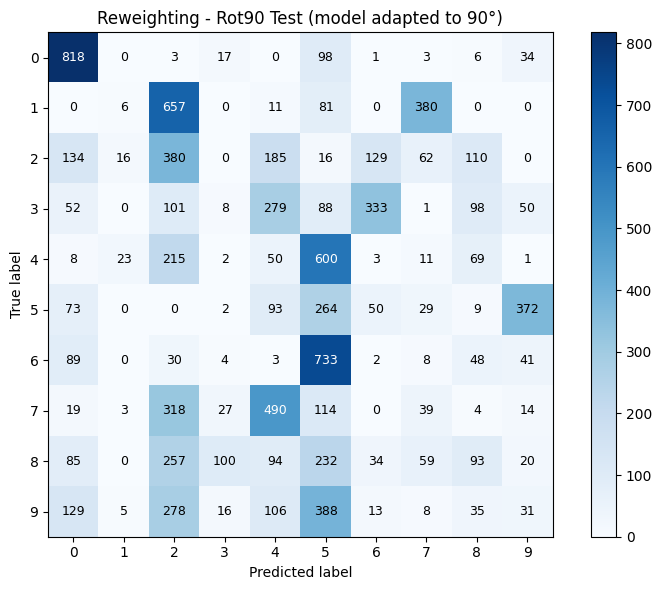

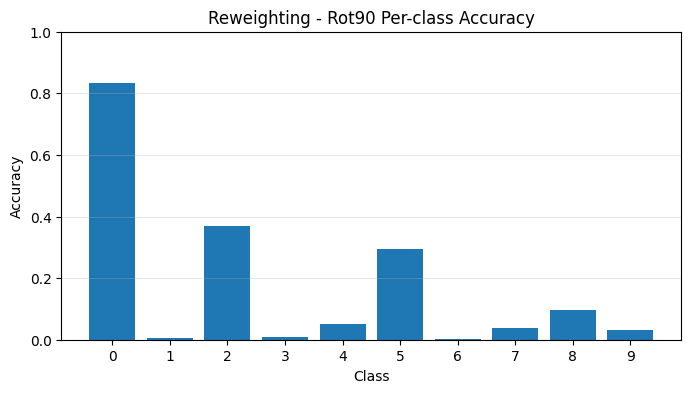

In [36]:
reweight15_model, reweight15_clean, reweight15_target = run_reweighting_adaptation(
    target_dataset=target15_test,
    target_loader=target15_test_loader,
    target_name="Rot15"
)

reweight90_model, reweight90_clean, reweight90_target = run_reweighting_adaptation(
    target_dataset=target90_test,
    target_loader=target90_test_loader,
    target_name="Rot90"
)

plot_confusion_matrix_with_numbers(reweight15_clean["cm"], title="Reweighting - Clean Test (model adapted to 15°)")
plot_confusion_matrix_with_numbers(reweight15_target["cm"], title="Reweighting - Rot15 Test (model adapted to 15°)")
plot_per_class_accuracy(reweight15_target["per_class_acc"], title="Reweighting - Rot15 Per-class Accuracy")

plot_confusion_matrix_with_numbers(reweight90_clean["cm"], title="Reweighting - Clean Test (model adapted to 90°)")
plot_confusion_matrix_with_numbers(reweight90_target["cm"], title="Reweighting - Rot90 Test (model adapted to 90°)")
plot_per_class_accuracy(reweight90_target["per_class_acc"], title="Reweighting - Rot90 Per-class Accuracy")

# Method 2: Feature Alignment (DANN)

In [ ]:
"""
Implement a gradient reversal layer that passes inputs unchanged during the forward pass and reverses gradients during backpropagation.
"""
class GradientReversalFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambd * grad_output, None

In [ ]:
"""
Wrap a gradient reversal operation as a module to enable adversarial training by flipping gradients during backpropagation.
"""
class GRL(nn.Module):
    def __init__(self, lambd=1.0):
        super().__init__()
        self.lambd = lambd

    def forward(self, x):
        return GradientReversalFunction.apply(x, self.lambd)

In [ ]:
"""
Define a Domain-Adversarial Neural Network with a shared feature encoder, label classifier, and adversarial domain classifier using gradient reversal.
"""
class DANN(nn.Module):
    def __init__(self, lambd=0.2):
        super().__init__()
        self.encoder = LeNetEncoder()
        self.label_classifier = LeNetLabelClassifier()
        self.domain_classifier = DomainClassifier(in_dim=16 * 4 * 4)
        self.grl = GRL(lambd=lambd)

    def forward(self, x):
        feat = self.encoder(x)
        class_logits = self.label_classifier(feat)
        domain_logits = self.domain_classifier(self.grl(feat))
        return class_logits, domain_logits

    def predict(self, x):
        feat = self.encoder(x)
        return self.label_classifier(feat)

In [ ]:
"""
Train a domain-adversarial model using labeled source data and unlabeled target data, combining classification loss with scheduled domain confusion loss.
"""

def train_dann(dann_model, source_loader, target_loader, val_loader=None, epochs=4, lr=1e-3):
    dann_model = dann_model.to(device)

    optimizer = torch.optim.Adam(dann_model.parameters(), lr=lr)
    class_criterion = nn.CrossEntropyLoss()
    domain_criterion = nn.BCEWithLogitsLoss()

    source_iter = cycle_loader(source_loader)
    target_iter = cycle_loader(target_loader)

    steps_per_epoch = max(len(source_loader), len(target_loader))

    history = {
        "train_loss": [],
        "train_acc": []
    }

    if val_loader is not None:
        history["val_loss"] = []
        history["val_acc"] = []

    total_steps = epochs * steps_per_epoch

    for epoch in range(epochs):
        dann_model.train()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for step in range(steps_per_epoch):
            global_step = epoch * steps_per_epoch + step
            p = global_step / total_steps

            # DANN lambda schedule: starts near 0 and gradually increases
            lambda_p = 2.0 / (1.0 + np.exp(-10.0 * p)) - 1.0
            dann_model.grl.lambd = LAMBDA_DOMAIN * lambda_p

            xs, ys = next(source_iter)
            xt, _ = next(target_iter)

            xs, ys = xs.to(device), ys.to(device)
            xt = xt.to(device)

            optimizer.zero_grad()

            ys_logits, ds_logits_s = dann_model(xs)
            _, dt_logits_t = dann_model(xt)

            class_loss = class_criterion(ys_logits, ys)

            ds_labels = torch.ones(xs.size(0), device=device)
            dt_labels = torch.zeros(xt.size(0), device=device)

            domain_loss_s = domain_criterion(ds_logits_s, ds_labels)
            domain_loss_t = domain_criterion(dt_logits_t, dt_labels)
            domain_loss = 0.5 * (domain_loss_s + domain_loss_t)

            loss = class_loss + LAMBDA_DOMAIN * domain_loss
            loss.backward()
            optimizer.step()

            preds = ys_logits.argmax(dim=1)

            total_loss += loss.item() * ys.size(0)
            total_correct += (preds == ys).sum().item()
            total_samples += ys.size(0)

        epoch_train_loss = total_loss / total_samples
        epoch_train_acc = total_correct / total_samples

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)

        if val_loader is not None:
            dann_model.eval()

            val_loss_sum = 0.0
            val_correct = 0
            val_samples = 0

            with torch.no_grad():
                for x, y in val_loader:
                    x, y = x.to(device), y.to(device)

                    logits = dann_model.predict(x)
                    loss = class_criterion(logits, y)
                    preds = logits.argmax(dim=1)

                    val_loss_sum += loss.item() * y.size(0)
                    val_correct += (preds == y).sum().item()
                    val_samples += y.size(0)

            epoch_val_loss = val_loss_sum / val_samples
            epoch_val_acc = val_correct / val_samples

            history["val_loss"].append(epoch_val_loss)
            history["val_acc"].append(epoch_val_acc)

            print(
                f"[DANN] Epoch {epoch+1}/{epochs} | "
                f"lambda={dann_model.grl.lambd:.4f} | "
                f"train_loss={epoch_train_loss:.4f} | train_acc={epoch_train_acc:.4f} | "
                f"val_loss={epoch_val_loss:.4f} | val_acc={epoch_val_acc:.4f}"
            )
        else:
            print(
                f"[DANN] Epoch {epoch+1}/{epochs} | "
                f"lambda={dann_model.grl.lambd:.4f} | "
                f"train_loss={epoch_train_loss:.4f} | train_acc={epoch_train_acc:.4f}"
            )

    return history

In [41]:
@torch.no_grad()
def evaluate_dann(dann_model, loader):
    dann_model.eval()

    y_true = []
    y_pred = []

    for x, y in loader:
        x = x.to(device)
        logits = dann_model.predict(x)
        preds = logits.argmax(dim=1).cpu().numpy()

        y_pred.extend(preds.tolist())
        y_true.extend(y.numpy().tolist())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acc = (y_true == y_pred).mean()
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    per_class_acc = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)

    return {
        "accuracy": acc,
        "y_true": y_true,
        "y_pred": y_pred,
        "cm": cm,
        "per_class_acc": per_class_acc
    }

In [42]:
@torch.no_grad()
def collect_encoder_features(encoder, loader, domain_name, max_samples=2000):
    """
    Collects encoder features, labels, and domain tags from a loader.
    """
    encoder.eval()

    feats = []
    labels = []
    domains = []

    collected = 0

    for x, y in loader:
        x = x.to(device)

        h = encoder(x).cpu().numpy()
        y = y.numpy()

        feats.append(h)
        labels.append(y)
        domains.extend([domain_name] * len(y))

        collected += len(y)
        if collected >= max_samples:
            break

    feats = np.concatenate(feats, axis=0)[:max_samples]
    labels = np.concatenate(labels, axis=0)[:max_samples]
    domains = np.array(domains[:max_samples])

    return feats, labels, domains

In [43]:
def plot_tsne_domains(features, domains, title="t-SNE of Encoder Features"):
    """
    Colors samples by domain: source vs target.
    """
    tsne = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto")
    z = tsne.fit_transform(features)

    plt.figure(figsize=(7, 6))

    mask_s = (domains == "source")
    mask_t = (domains == "target")

    plt.scatter(z[mask_s, 0], z[mask_s, 1], s=10, alpha=0.6, label="Source")
    plt.scatter(z[mask_t, 0], z[mask_t, 1], s=10, alpha=0.6, label="Target")

    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [44]:
def plot_tsne_classes(features, labels, title="t-SNE of Encoder Features by Class"):
    """
    Colors samples by class label.
    """
    tsne = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto")
    z = tsne.fit_transform(features)

    plt.figure(figsize=(7, 6))

    for c in range(10):
        mask = (labels == c)
        plt.scatter(z[mask, 0], z[mask, 1], s=10, alpha=0.6, label=str(c))

    plt.title(title)
    plt.legend(ncol=2, fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [45]:
def visualize_feature_alignment(before_encoder, after_encoder, source_loader, target_loader, title_prefix="", max_samples=1000):
    """
    Compares source/target encoder features before and after DANN adaptation.
    Produces:
      1) t-SNE by domain before adaptation
      2) t-SNE by domain after adaptation
      3) t-SNE by class after adaptation
    """
    # before
    src_feat_b, src_y_b, src_d_b = collect_encoder_features(
        before_encoder, source_loader, "source", max_samples=max_samples
    )
    tgt_feat_b, tgt_y_b, tgt_d_b = collect_encoder_features(
        before_encoder, target_loader, "target", max_samples=max_samples
    )

    feat_before = np.concatenate([src_feat_b, tgt_feat_b], axis=0)
    y_before = np.concatenate([src_y_b, tgt_y_b], axis=0)
    d_before = np.concatenate([src_d_b, tgt_d_b], axis=0)

    # after
    src_feat_a, src_y_a, src_d_a = collect_encoder_features(
        after_encoder, source_loader, "source", max_samples=max_samples
    )
    tgt_feat_a, tgt_y_a, tgt_d_a = collect_encoder_features(
        after_encoder, target_loader, "target", max_samples=max_samples
    )

    feat_after = np.concatenate([src_feat_a, tgt_feat_a], axis=0)
    y_after = np.concatenate([src_y_a, tgt_y_a], axis=0)
    d_after = np.concatenate([src_d_a, tgt_d_a], axis=0)

    # plots
    plot_tsne_domains(
        feat_before, d_before,
        title=f"{title_prefix} - t-SNE by Domain (Before Adaptation)"
    )

    plot_tsne_domains(
        feat_after, d_after,
        title=f"{title_prefix} - t-SNE by Domain (After DANN Adaptation)"
    )

    plot_tsne_classes(
        feat_after, y_after,
        title=f"{title_prefix} - t-SNE by Class (After DANN Adaptation)"
    )

In [46]:
def run_dann_adaptation(target_loader, target_name="Rot15"):
    print(f"\n================ Feature Alignment (DANN) on {target_name} ================")

    model = DANN(lambd=LAMBDA_DOMAIN).to(device)
    copy_lenet_to_dann(model, baseline_model)

    # save encoder before adaptation
    encoder_before = copy.deepcopy(model.encoder).to(device)

    history = train_dann(
        model,
        source_loader=source_train_loader,
        target_loader=target_loader,
        val_loader=source_val_loader,
        epochs=DANN_EPOCHS,
        lr=LR_DANN
    )

    plot_training_history(history, title=f"DANN - {target_name}")

    clean_eval = evaluate_dann(model, source_test_loader)
    target_eval = evaluate_dann(model, target_loader)

    print(f"\n[DANN - {target_name}]")
    print(f"Clean Test Accuracy : {clean_eval['accuracy']:.4f}")
    print(f"{target_name} Test Accuracy : {target_eval['accuracy']:.4f}")

    return model, encoder_before, clean_eval, target_eval


================ Feature Alignment (DANN) on Rot15 ================


[DANN] Epoch 1/6 | lambda=0.1360 | train_loss=0.1342 | train_acc=0.9924 | val_loss=0.0415 | val_acc=0.9868
[DANN] Epoch 2/6 | lambda=0.1861 | train_loss=0.1057 | train_acc=0.9933 | val_loss=0.0463 | val_acc=0.9845
[DANN] Epoch 3/6 | lambda=0.1973 | train_loss=0.0934 | train_acc=0.9938 | val_loss=0.0430 | val_acc=0.9868
[DANN] Epoch 4/6 | lambda=0.1995 | train_loss=0.0875 | train_acc=0.9943 | val_loss=0.0412 | val_acc=0.9865
[DANN] Epoch 5/6 | lambda=0.1999 | train_loss=0.0831 | train_acc=0.9944 | val_loss=0.0417 | val_acc=0.9867
[DANN] Epoch 6/6 | lambda=0.2000 | train_loss=0.0785 | train_acc=0.9950 | val_loss=0.0412 | val_acc=0.9875


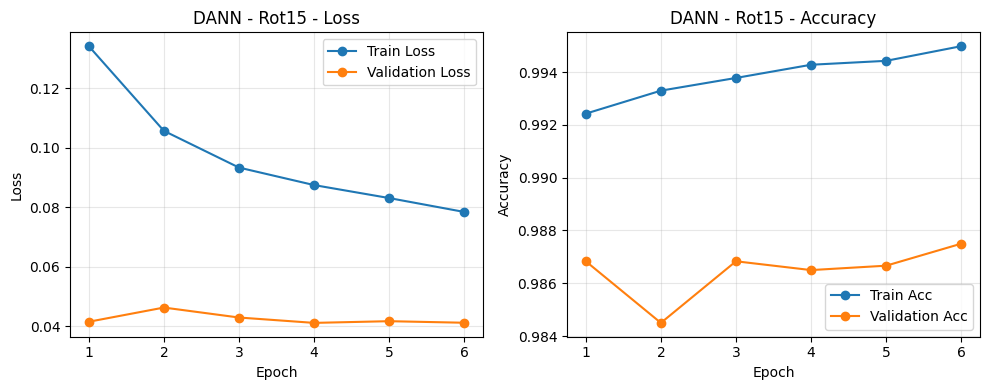


[DANN - Rot15]
Clean Test Accuracy : 0.9888
Rot15 Test Accuracy : 0.9591

================ Feature Alignment (DANN) on Rot90 ================
[DANN] Epoch 1/6 | lambda=0.1360 | train_loss=0.0551 | train_acc=0.9926 | val_loss=0.0465 | val_acc=0.9843
[DANN] Epoch 2/6 | lambda=0.1861 | train_loss=0.0315 | train_acc=0.9933 | val_loss=0.0449 | val_acc=0.9858
[DANN] Epoch 3/6 | lambda=0.1973 | train_loss=0.0265 | train_acc=0.9939 | val_loss=0.0416 | val_acc=0.9868
[DANN] Epoch 4/6 | lambda=0.1995 | train_loss=0.0235 | train_acc=0.9944 | val_loss=0.0435 | val_acc=0.9860
[DANN] Epoch 5/6 | lambda=0.1999 | train_loss=0.0218 | train_acc=0.9946 | val_loss=0.0481 | val_acc=0.9853
[DANN] Epoch 6/6 | lambda=0.2000 | train_loss=0.0200 | train_acc=0.9950 | val_loss=0.0439 | val_acc=0.9860


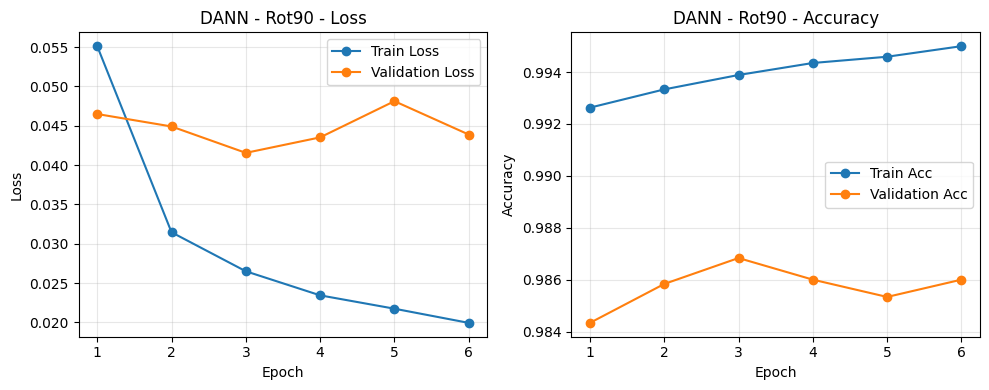


[DANN - Rot90]
Clean Test Accuracy : 0.9887
Rot90 Test Accuracy : 0.1676


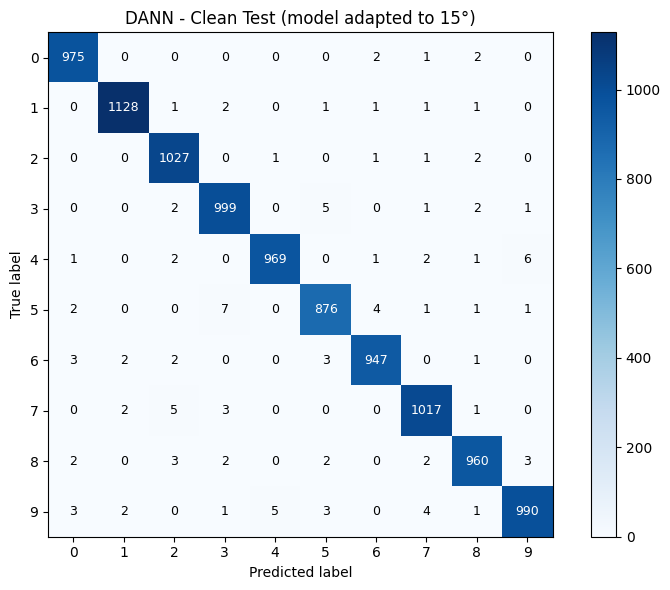

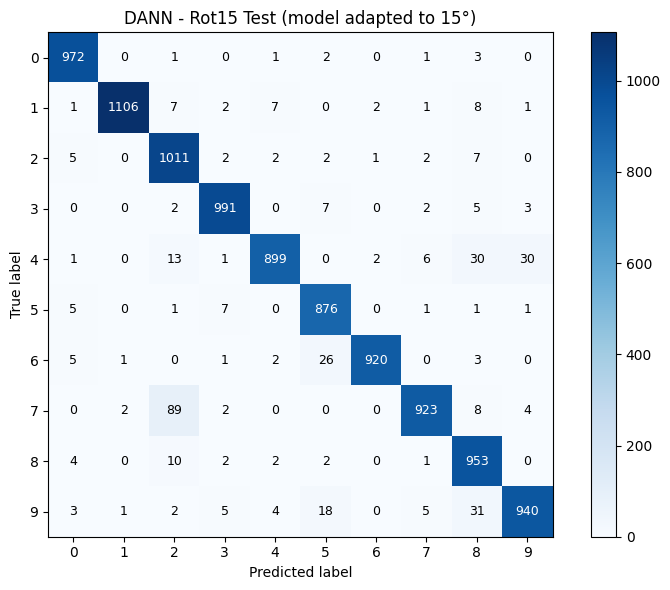

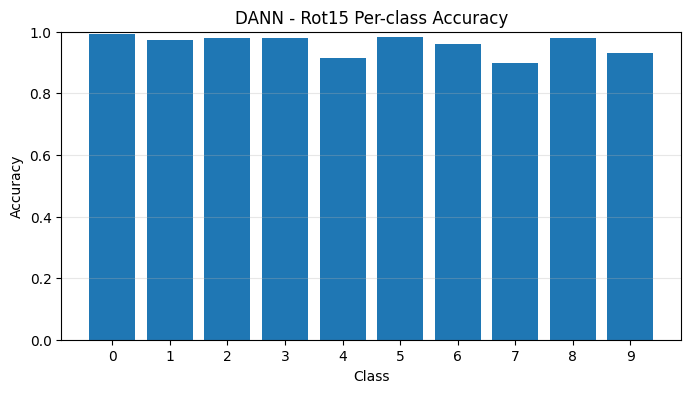

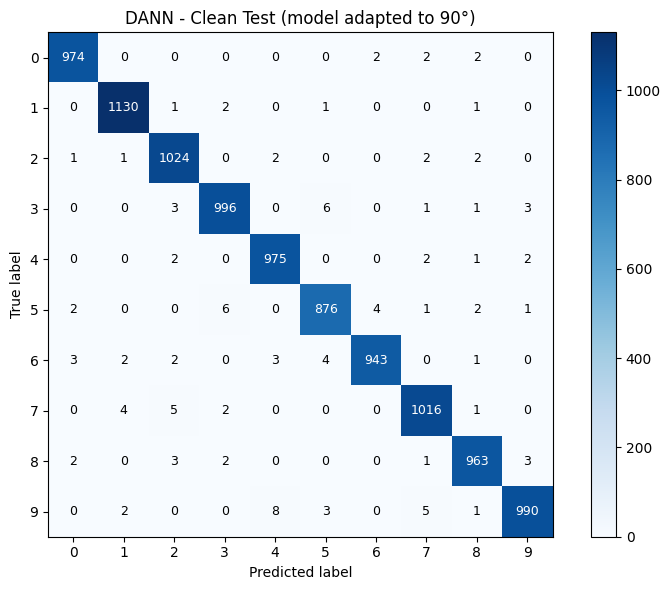

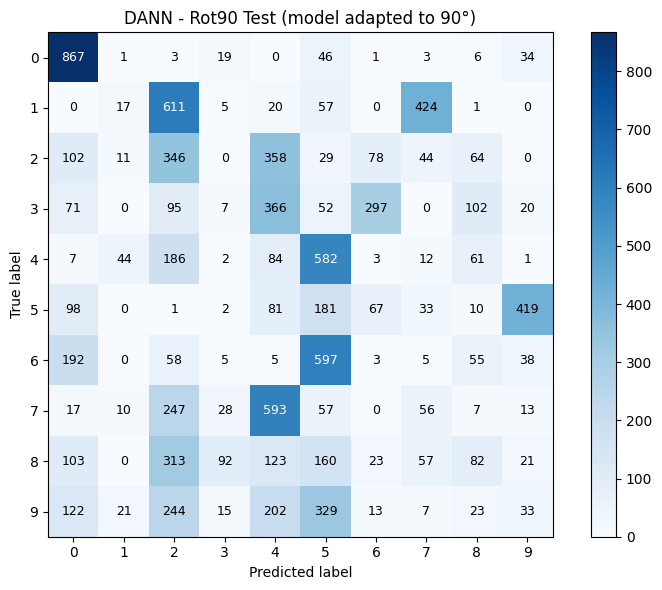

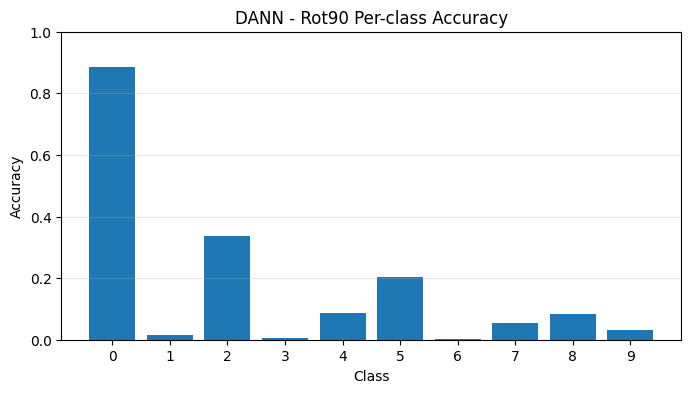

In [47]:
dann15_model, dann15_encoder_before, dann15_clean, dann15_target = run_dann_adaptation(
    target_loader=target15_test_loader,
    target_name="Rot15"
)

dann90_model, dann90_encoder_before, dann90_clean, dann90_target = run_dann_adaptation(
    target_loader=target90_test_loader,
    target_name="Rot90"
)

plot_confusion_matrix_with_numbers(dann15_clean["cm"], title="DANN - Clean Test (model adapted to 15°)")
plot_confusion_matrix_with_numbers(dann15_target["cm"], title="DANN - Rot15 Test (model adapted to 15°)")
plot_per_class_accuracy(dann15_target["per_class_acc"], title="DANN - Rot15 Per-class Accuracy")

plot_confusion_matrix_with_numbers(dann90_clean["cm"], title="DANN - Clean Test (model adapted to 90°)")
plot_confusion_matrix_with_numbers(dann90_target["cm"], title="DANN - Rot90 Test (model adapted to 90°)")
plot_per_class_accuracy(dann90_target["per_class_acc"], title="DANN - Rot90 Per-class Accuracy")

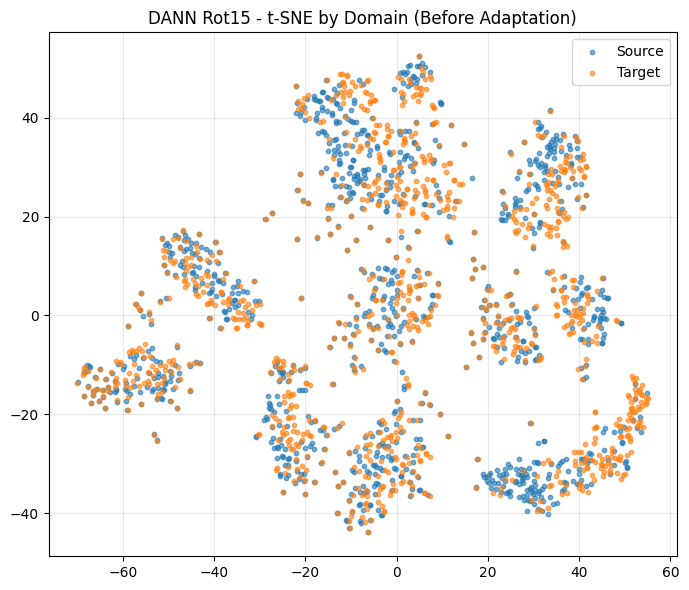

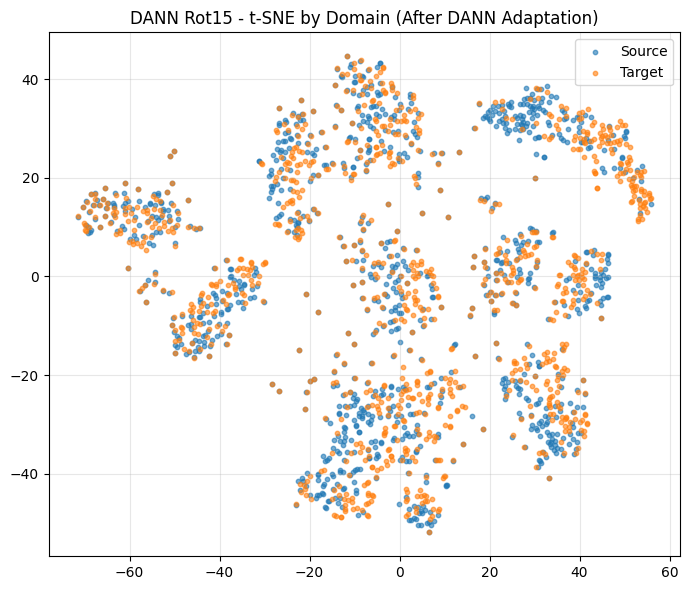

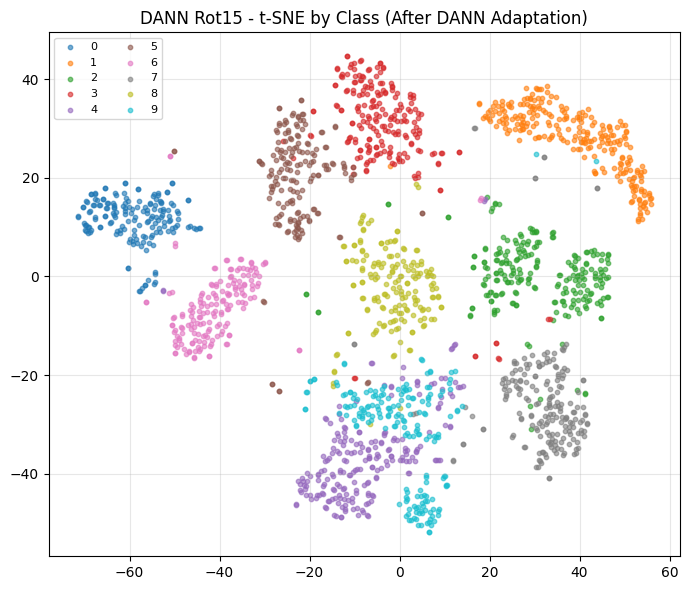

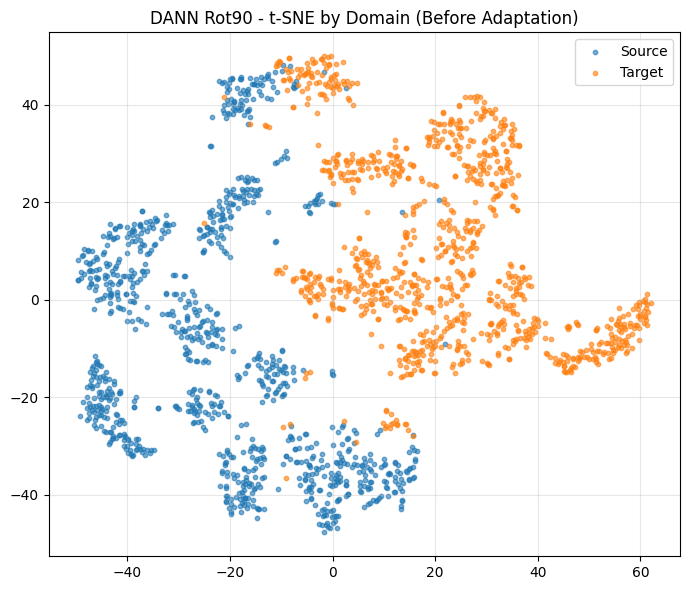

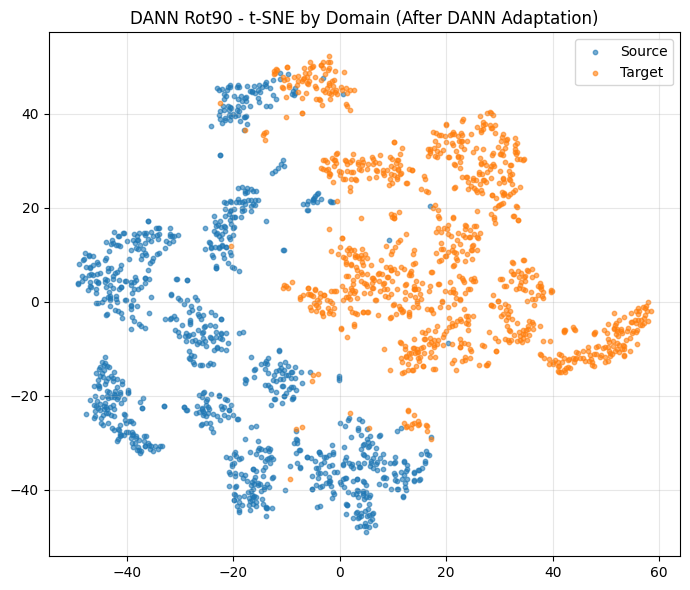

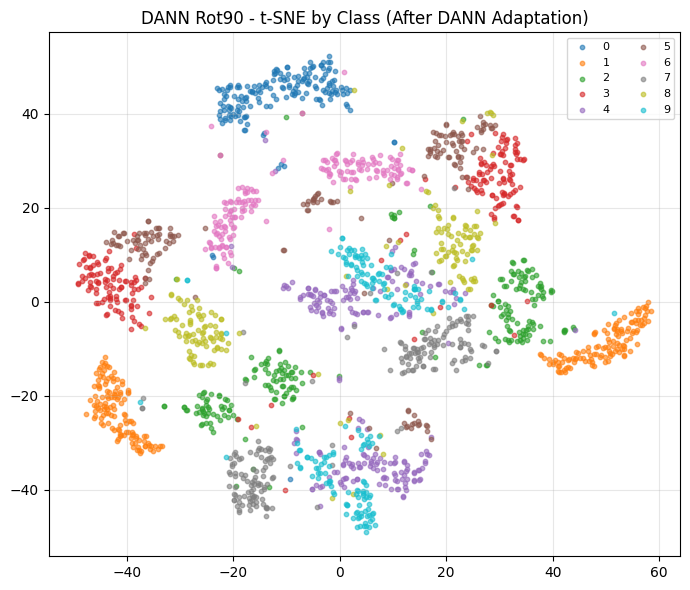

In [48]:
# -------------------------------------------------
# Visualizing feature alignment for DANN
# -------------------------------------------------
visualize_feature_alignment(
    before_encoder=dann15_encoder_before,
    after_encoder=dann15_model.encoder,
    source_loader=source_test_loader,
    target_loader=target15_test_loader,
    title_prefix="DANN Rot15",
    max_samples=1000
)

visualize_feature_alignment(
    before_encoder=dann90_encoder_before,
    after_encoder=dann90_model.encoder,
    source_loader=source_test_loader,
    target_loader=target90_test_loader,
    title_prefix="DANN Rot90",
    max_samples=1000
)

# Method 3: Domain Translation (CycleGAN)

In [49]:
class UnpairedImageDataset(Dataset):
    """
    Returns unpaired source / target samples.
    """
    def __init__(self, source_dataset, target_dataset):
        self.source_dataset = source_dataset
        self.target_dataset = target_dataset
        self.n_source = len(source_dataset)
        self.n_target = len(target_dataset)
        self.length = max(self.n_source, self.n_target)

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        xs, _ = self.source_dataset[idx % self.n_source]
        xt, _ = self.target_dataset[random.randint(0, self.n_target - 1)]
        return xs, xt

In [ ]:
"""
Define a residual block with convolutional layers and instance normalization that adds a skip connection to preserve input features.
"""
class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1),
            nn.InstanceNorm2d(ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(ch, ch, 3, padding=1),
            nn.InstanceNorm2d(ch)
        )

    def forward(self, x):
        return x + self.block(x)

In [51]:
class SmallGenerator(nn.Module):
    """
    Small generator for 1x28x28 MNIST images.
    Input / output are in GAN-normalized space.
    """
    def __init__(self, in_ch=1, base_ch=64, n_res=4):
        super().__init__()

        layers = [
            nn.Conv2d(in_ch, base_ch, 7, padding=3),
            nn.InstanceNorm2d(base_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(base_ch, base_ch * 2, 3, stride=2, padding=1),
            nn.InstanceNorm2d(base_ch * 2),
            nn.ReLU(inplace=True),

            nn.Conv2d(base_ch * 2, base_ch * 4, 3, stride=2, padding=1),
            nn.InstanceNorm2d(base_ch * 4),
            nn.ReLU(inplace=True),
        ]

        for _ in range(n_res):
            layers.append(ResBlock(base_ch * 4))

        layers += [
            nn.ConvTranspose2d(base_ch * 4, base_ch * 2, 4, stride=2, padding=1),
            nn.InstanceNorm2d(base_ch * 2),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(base_ch * 2, base_ch, 4, stride=2, padding=1),
            nn.InstanceNorm2d(base_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(base_ch, 1, 7, padding=3),
            nn.Tanh()
        ]

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [ ]:
"""
Define a PatchGAN-style discriminator that classifies local image patches using convolutional layers with instance normalization and leaky ReLU activations.
"""
class PatchDiscriminator(nn.Module):
    def __init__(self, in_ch=1, base_ch=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, base_ch, 4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base_ch, base_ch * 2, 4, stride=2, padding=1),
            nn.InstanceNorm2d(base_ch * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base_ch * 2, base_ch * 4, 3, stride=1, padding=1),
            nn.InstanceNorm2d(base_ch * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base_ch * 4, 1, 3, stride=1, padding=1)
        )

    def forward(self, x):
        return self.net(x)

In [53]:
def gan_loss_lsgan(pred, target_is_real):
    target = torch.ones_like(pred) if target_is_real else torch.zeros_like(pred)
    return func.mse_loss(pred, target)

In [54]:
def train_cyclegan(
    source_dataset,
    target_dataset,
    epochs=5,
    batch_size=128,
    lr=2e-4,
    lambda_cycle=10.0,
    lambda_identity=2.0,
    num_workers=2
):
    """
    Trains:
        G_ST: source -> target
        G_TS: target -> source
        D_S: source discriminator
        D_T: target discriminator
    """
    pair_dataset = UnpairedImageDataset(source_dataset, target_dataset)
    pair_loader = DataLoader(
        pair_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True
    )

    G_ST = SmallGenerator().to(device)
    G_TS = SmallGenerator().to(device)
    D_S = PatchDiscriminator().to(device)
    D_T = PatchDiscriminator().to(device)

    opt_G = torch.optim.Adam(
        list(G_ST.parameters()) + list(G_TS.parameters()),
        lr=lr, betas=(0.5, 0.999)
    )
    opt_D_S = torch.optim.Adam(D_S.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D_T = torch.optim.Adam(D_T.parameters(), lr=lr, betas=(0.5, 0.999))

    history = {"G_loss": [], "D_S_loss": [], "D_T_loss": []}

    for epoch in range(epochs):
        G_ST.train()
        G_TS.train()
        D_S.train()
        D_T.train()

        g_running = 0.0
        ds_running = 0.0
        dt_running = 0.0
        total = 0

        for xs, xt in pair_loader:
            xs = xs.to(device)
            xt = xt.to(device)
            bsz = xs.size(0)

            # ---------------------------
            # Train Generators
            # ---------------------------
            opt_G.zero_grad()

            fake_t = G_ST(xs)
            fake_s = G_TS(xt)

            rec_s = G_TS(fake_t)
            rec_t = G_ST(fake_s)

            loss_g_st = gan_loss_lsgan(D_T(fake_t), True)
            loss_g_ts = gan_loss_lsgan(D_S(fake_s), True)

            loss_cycle_s = func.l1_loss(rec_s, xs)
            loss_cycle_t = func.l1_loss(rec_t, xt)
            loss_cycle = loss_cycle_s + loss_cycle_t

            id_s = G_TS(xs)
            id_t = G_ST(xt)
            loss_id_s = func.l1_loss(id_s, xs)
            loss_id_t = func.l1_loss(id_t, xt)
            loss_id = loss_id_s + loss_id_t

            loss_G = (
                loss_g_st + loss_g_ts
                + lambda_cycle * loss_cycle
                + lambda_identity * loss_id
            )

            loss_G.backward()
            opt_G.step()

            # ---------------------------
            # Train D_S
            # ---------------------------
            opt_D_S.zero_grad()

            pred_real_s = D_S(xs)
            pred_fake_s = D_S(fake_s.detach())

            loss_d_s_real = gan_loss_lsgan(pred_real_s, True)
            loss_d_s_fake = gan_loss_lsgan(pred_fake_s, False)
            loss_D_S = 0.5 * (loss_d_s_real + loss_d_s_fake)

            loss_D_S.backward()
            opt_D_S.step()

            # ---------------------------
            # Train D_T
            # ---------------------------
            opt_D_T.zero_grad()

            pred_real_t = D_T(xt)
            pred_fake_t = D_T(fake_t.detach())

            loss_d_t_real = gan_loss_lsgan(pred_real_t, True)
            loss_d_t_fake = gan_loss_lsgan(pred_fake_t, False)
            loss_D_T = 0.5 * (loss_d_t_real + loss_d_t_fake)

            loss_D_T.backward()
            opt_D_T.step()

            g_running += loss_G.item() * bsz
            ds_running += loss_D_S.item() * bsz
            dt_running += loss_D_T.item() * bsz
            total += bsz

        history["G_loss"].append(g_running / total)
        history["D_S_loss"].append(ds_running / total)
        history["D_T_loss"].append(dt_running / total)

        print(
            f"[CycleGAN] Epoch {epoch+1}/{epochs} | "
            f"G={history['G_loss'][-1]:.4f} | "
            f"D_S={history['D_S_loss'][-1]:.4f} | "
            f"D_T={history['D_T_loss'][-1]:.4f}"
        )

    return G_ST, G_TS, D_S, D_T, history

In [55]:
@torch.no_grad()
def evaluate_translation_with_generator(classifier_model, generator_t2s, target_loader_gan):
    """
    Translates target images to source-like images, then classifies them with LeNet.
    Generator output is converted from GAN normalization to classifier normalization.
    """
    classifier_model.eval()
    generator_t2s.eval()

    y_true = []
    y_pred = []

    for x, y in target_loader_gan:
        x = x.to(device)

        # generator output in [-1, 1]
        x_src_like = generator_t2s(x)

        # convert from GAN normalized space to [0, 1]
        x_src_like = (x_src_like * 0.5) + 0.5
        x_src_like = torch.clamp(x_src_like, 0.0, 1.0)

        # then normalize for classifier
        x_src_like = (x_src_like - mean) / std

        logits = classifier_model(x_src_like)
        preds = logits.argmax(dim=1).cpu().numpy()

        y_pred.extend(preds.tolist())
        y_true.extend(y.numpy().tolist())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acc = (y_true == y_pred).mean()
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    per_class_acc = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)

    return {
        "accuracy": acc,
        "y_true": y_true,
        "y_pred": y_pred,
        "cm": cm,
        "per_class_acc": per_class_acc
    }

In [56]:
@torch.no_grad()
def show_translation_samples(generator_st, generator_ts, source_dataset, target_dataset, n=8, title_prefix=""):
    """
    Shows source images, source-to-target translations,
    target images, and target-to-source translations.
    """
    generator_st.eval()
    generator_ts.eval()

    fig, axes = plt.subplots(4, n, figsize=(2 * n, 8))

    row_titles = ["Source", "S → T", "Target", "T → S"]

    for i in range(n):
        xs, _ = source_dataset[i]
        xt, _ = target_dataset[i]

        xs_in = xs.unsqueeze(0).to(device)
        xt_in = xt.unsqueeze(0).to(device)

        fake_t = generator_st(xs_in).cpu().squeeze(0)
        fake_s = generator_ts(xt_in).cpu().squeeze(0)

        # from [-1, 1] to [0, 1]
        xs_show = torch.clamp(xs * 0.5 + 0.5, 0.0, 1.0)
        xt_show = torch.clamp(xt * 0.5 + 0.5, 0.0, 1.0)
        fake_t_show = torch.clamp(fake_t * 0.5 + 0.5, 0.0, 1.0)
        fake_s_show = torch.clamp(fake_s * 0.5 + 0.5, 0.0, 1.0)

        images = [xs_show, fake_t_show, xt_show, fake_s_show]

        for row in range(4):
            axes[row, i].imshow(images[row].squeeze(0), cmap="gray")
            axes[row, i].axis("off")

    for row in range(4):
        axes[row, 0].set_title(row_titles[row], loc="left", fontsize=12, pad=10)

    fig.suptitle(f"{title_prefix} CycleGAN Translation Samples", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    title = f"{title_prefix} CycleGAN Translation Samples"
    filename = f"{QUESTION}_{title}.png"
    save_path = os.path.join(PICS_DIR, filename)
    plt.savefig(save_path, dpi=300)
    plt.show()

In [57]:
def run_domain_translation_gan(target_dataset_gan, target_loader_gan, target_name="Rot15"):
    print(f"\n================ Domain Translation (CycleGAN) on {target_name} ================")

    G_ST, G_TS, D_S, D_T, history = train_cyclegan(
        source_dataset=source_train_gan,
        target_dataset=target_dataset_gan,
        epochs=CYCLEGAN_EPOCHS,
        batch_size=BATCH_SIZE_GAN,
        lr=LR_GAN,
        lambda_cycle=LAMBDA_CYCLE,
        lambda_identity=LAMBDA_IDENTITY,
        num_workers=NUM_WORKERS
    )

    plot_cyclegan_history(history, title=f"CycleGAN - {target_name}")

    clean_eval = evaluate_model(baseline_model, source_test_loader)
    target_eval = evaluate_translation_with_generator(
        baseline_model, G_TS, target_loader_gan
    )

    print(f"\n[CycleGAN - {target_name}]")
    print(f"Clean Test Accuracy (baseline reference) : {clean_eval['accuracy']:.4f}")
    print(f"{target_name} Test Accuracy (after translation) : {target_eval['accuracy']:.4f}")

    show_translation_samples(
        G_ST, G_TS,
        source_dataset=source_test_gan,
        target_dataset=target_dataset_gan,
        n=8,
        title_prefix=target_name
    )

    return {
        "G_ST": G_ST,
        "G_TS": G_TS,
        "D_S": D_S,
        "D_T": D_T,
        "history": history,
        "clean_eval": clean_eval,
        "target_eval": target_eval
    }


================ Domain Translation (CycleGAN) on Rot15 ================
[CycleGAN] Epoch 1/12 | G=2.3918 | D_S=0.2377 | D_T=0.2369
[CycleGAN] Epoch 2/12 | G=1.6402 | D_S=0.2248 | D_T=0.2261
[CycleGAN] Epoch 3/12 | G=1.5486 | D_S=0.2239 | D_T=0.2251
[CycleGAN] Epoch 4/12 | G=1.4799 | D_S=0.2261 | D_T=0.2262
[CycleGAN] Epoch 5/12 | G=1.4264 | D_S=0.2278 | D_T=0.2273
[CycleGAN] Epoch 6/12 | G=1.3874 | D_S=0.2278 | D_T=0.2274
[CycleGAN] Epoch 7/12 | G=1.3552 | D_S=0.2286 | D_T=0.2273
[CycleGAN] Epoch 8/12 | G=1.3484 | D_S=0.2272 | D_T=0.2254
[CycleGAN] Epoch 9/12 | G=1.3136 | D_S=0.2291 | D_T=0.2266
[CycleGAN] Epoch 10/12 | G=1.2935 | D_S=0.2291 | D_T=0.2263
[CycleGAN] Epoch 11/12 | G=1.3331 | D_S=0.2254 | D_T=0.2215
[CycleGAN] Epoch 12/12 | G=1.2766 | D_S=0.2288 | D_T=0.2243


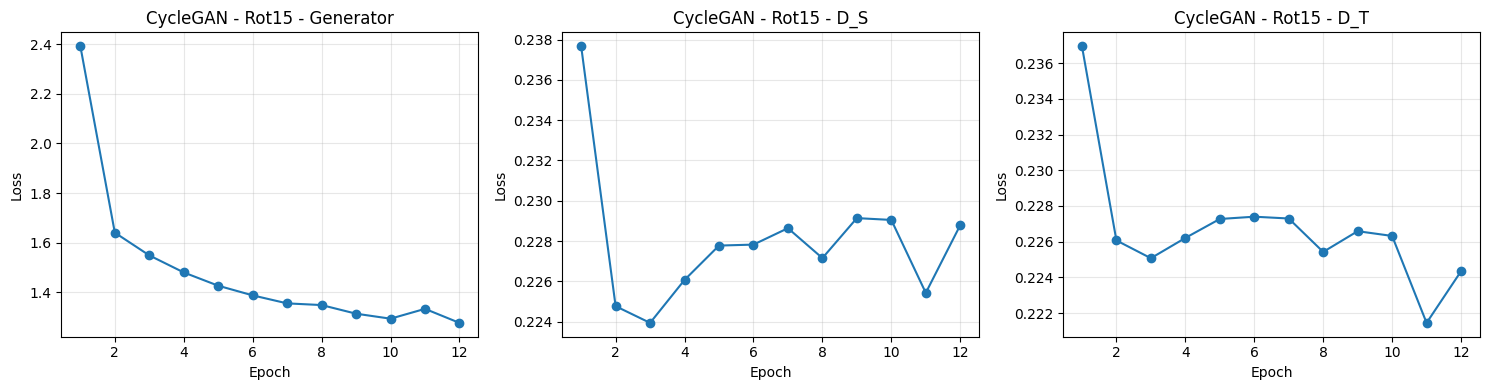


[CycleGAN - Rot15]
Clean Test Accuracy (baseline reference) : 0.9862
Rot15 Test Accuracy (after translation) : 0.9577


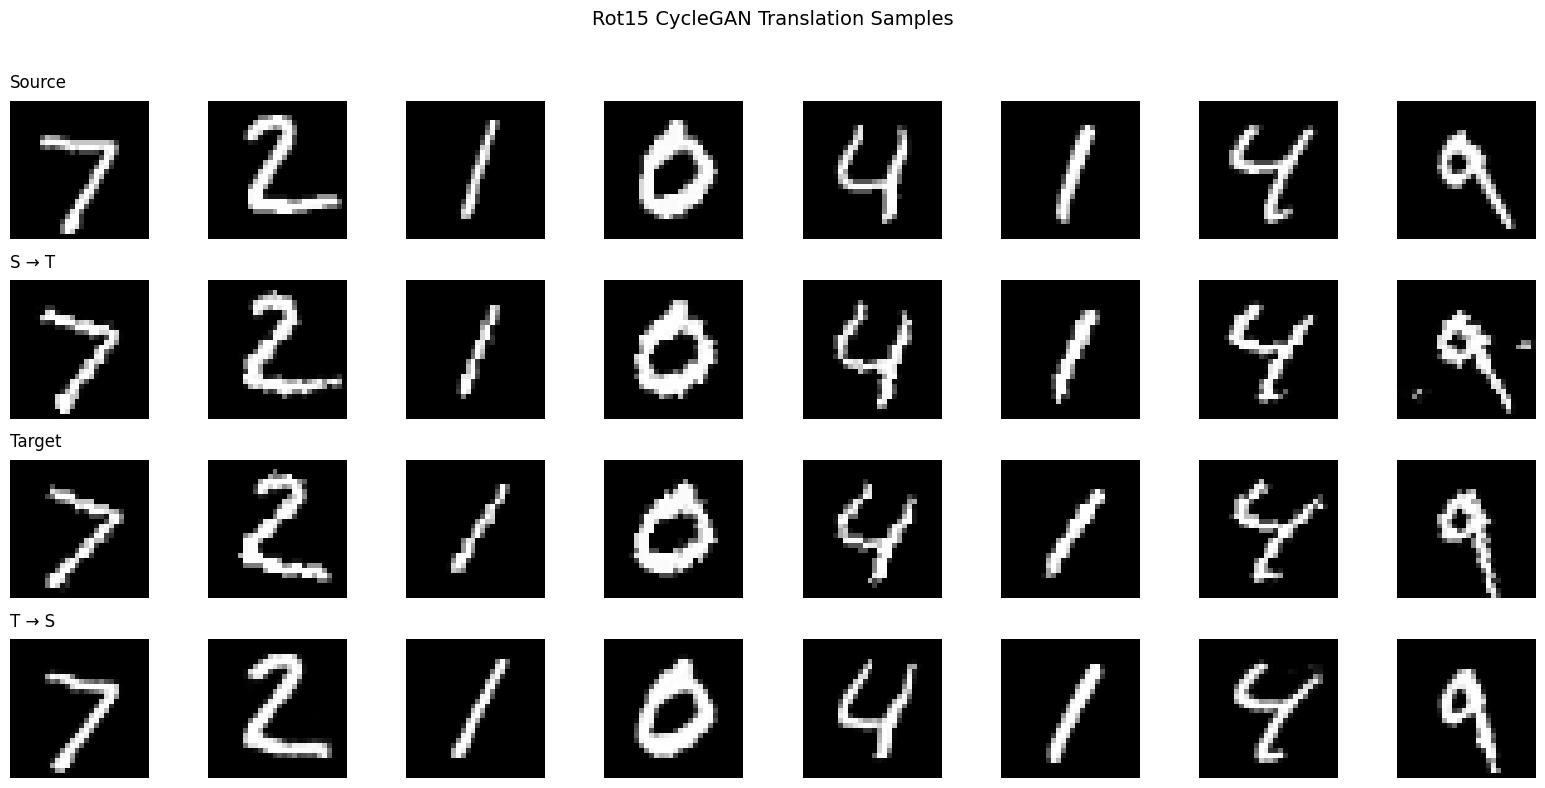

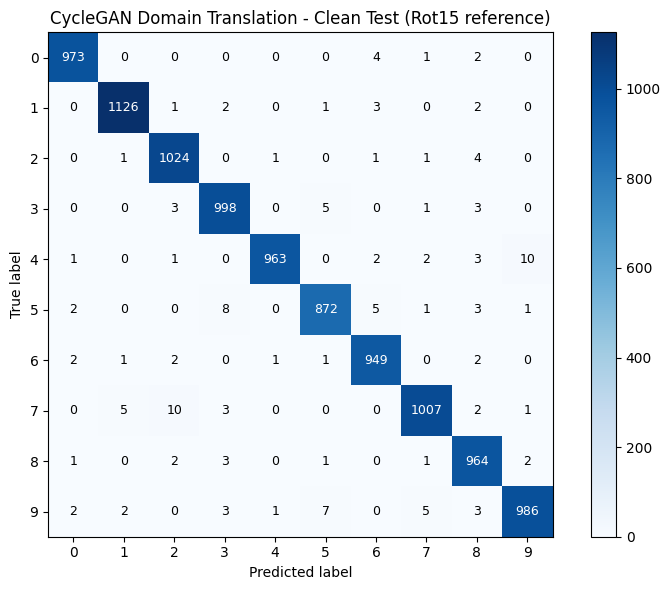

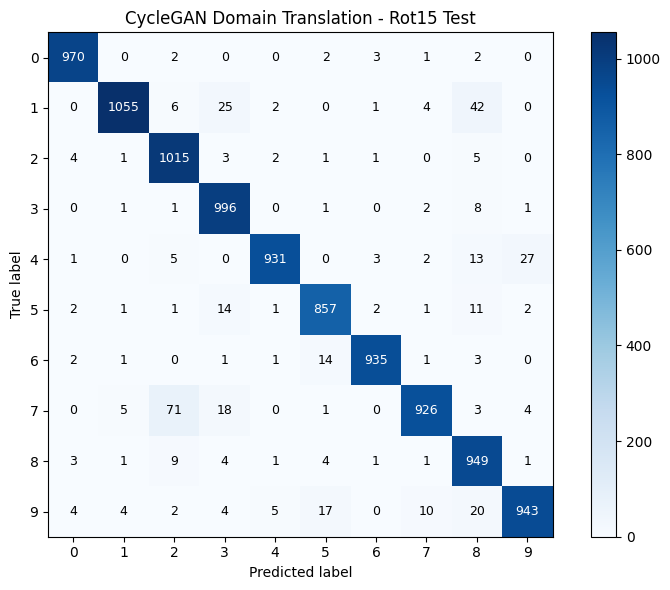

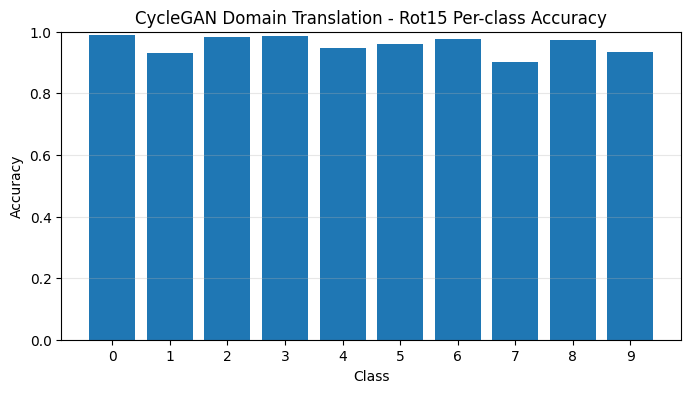


================ Domain Translation (CycleGAN) on Rot90 ================
[CycleGAN] Epoch 1/12 | G=2.8276 | D_S=0.1919 | D_T=0.1883
[CycleGAN] Epoch 2/12 | G=2.2360 | D_S=0.1766 | D_T=0.1712
[CycleGAN] Epoch 3/12 | G=2.1638 | D_S=0.1797 | D_T=0.1739
[CycleGAN] Epoch 4/12 | G=2.0860 | D_S=0.1856 | D_T=0.1794
[CycleGAN] Epoch 5/12 | G=2.0241 | D_S=0.1899 | D_T=0.1852
[CycleGAN] Epoch 6/12 | G=1.9684 | D_S=0.1955 | D_T=0.1893
[CycleGAN] Epoch 7/12 | G=1.9185 | D_S=0.1982 | D_T=0.1937
[CycleGAN] Epoch 8/12 | G=1.8762 | D_S=0.2019 | D_T=0.1974
[CycleGAN] Epoch 9/12 | G=1.8341 | D_S=0.2043 | D_T=0.1999
[CycleGAN] Epoch 10/12 | G=1.7991 | D_S=0.2069 | D_T=0.2019
[CycleGAN] Epoch 11/12 | G=1.7723 | D_S=0.2087 | D_T=0.2034
[CycleGAN] Epoch 12/12 | G=1.7392 | D_S=0.2103 | D_T=0.2050


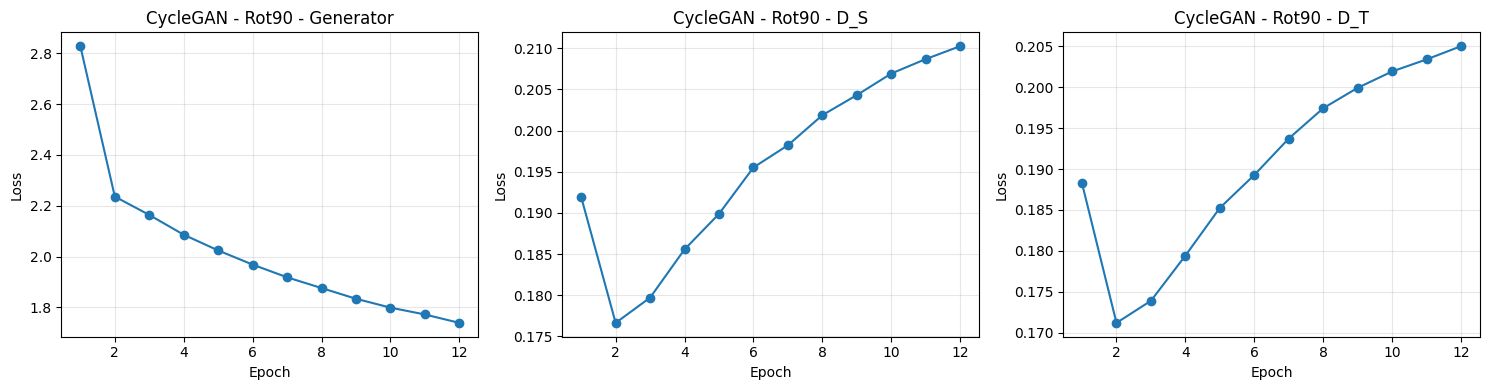


[CycleGAN - Rot90]
Clean Test Accuracy (baseline reference) : 0.9862
Rot90 Test Accuracy (after translation) : 0.1729


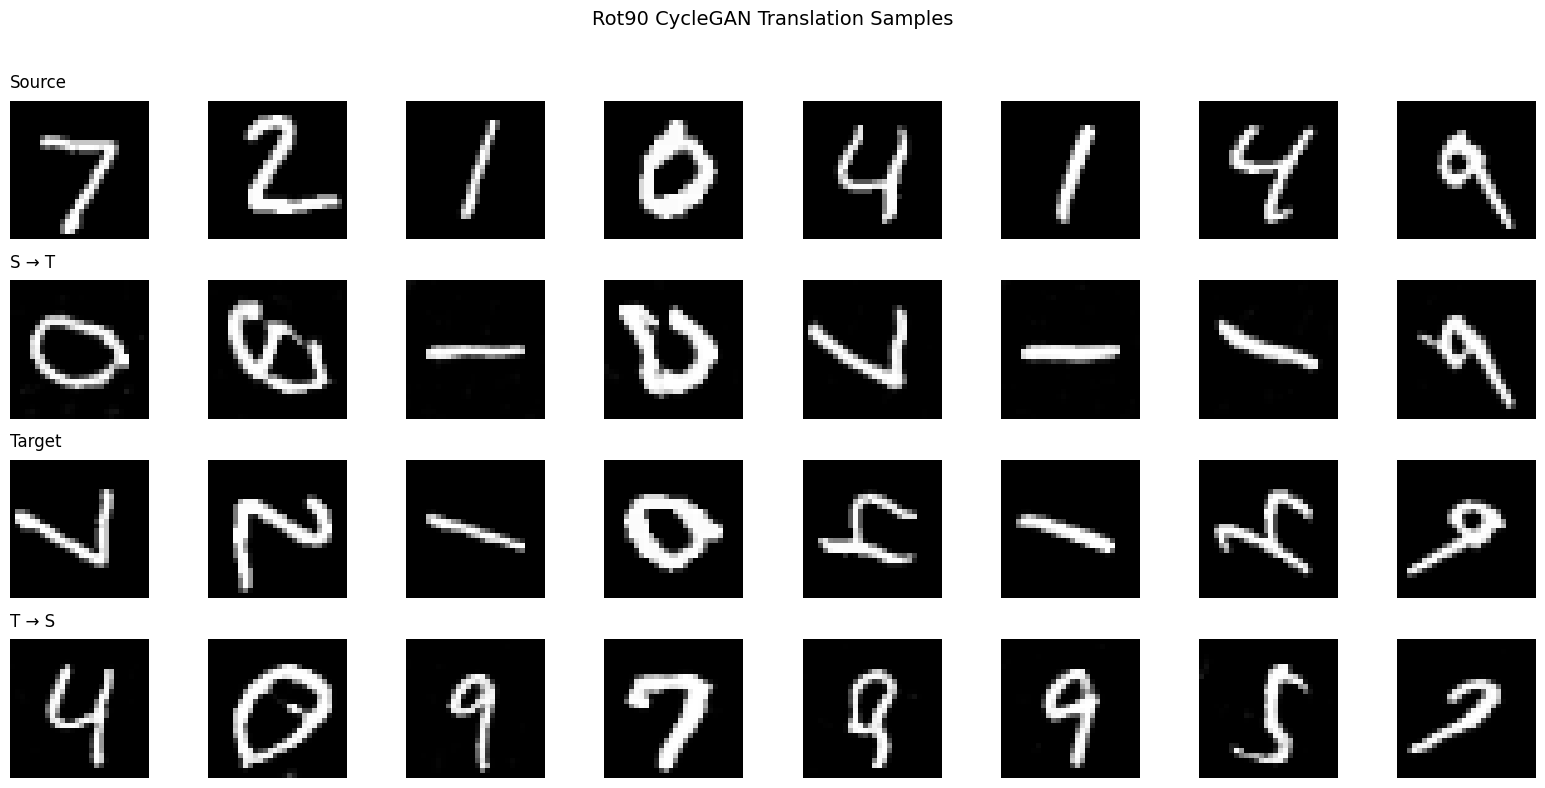

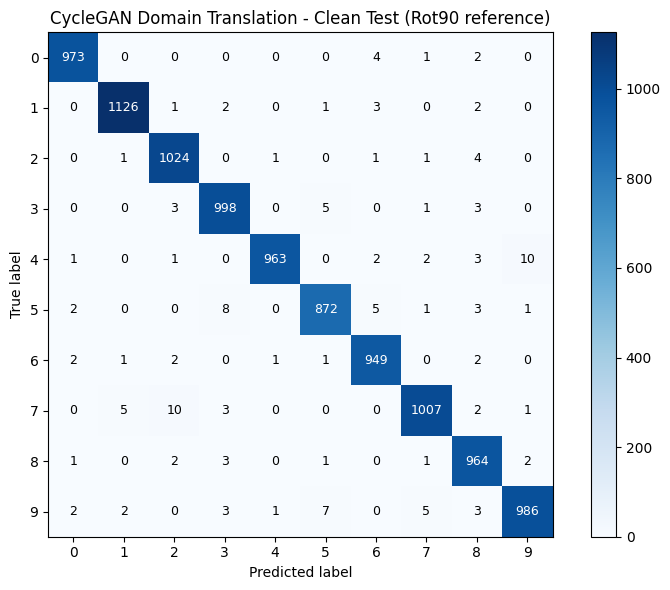

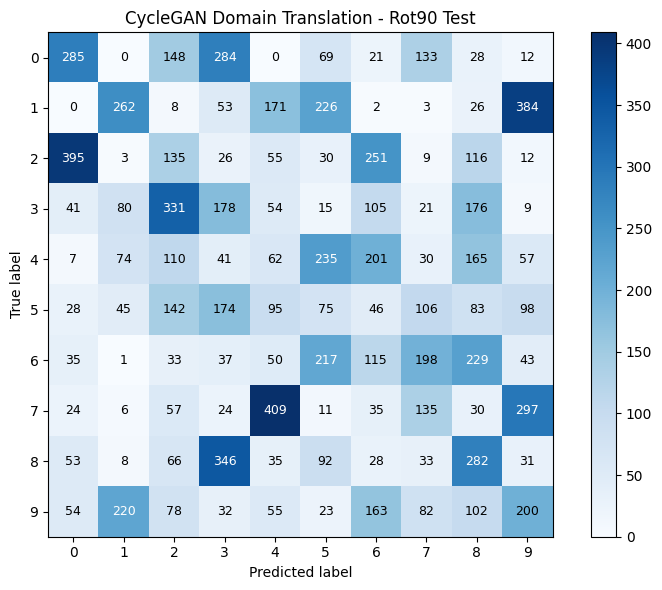

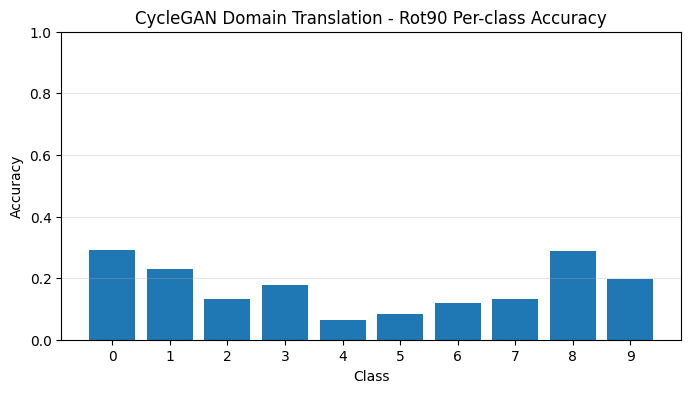

In [58]:
translation15_out = run_domain_translation_gan(
    target_dataset_gan=target15_test_gan,
    target_loader_gan=target15_test_loader_gan,
    target_name="Rot15"
)

translation15_clean = translation15_out["clean_eval"]
translation15_target = translation15_out["target_eval"]

plot_confusion_matrix_with_numbers(
    translation15_clean["cm"],
    title="CycleGAN Domain Translation - Clean Test (Rot15 reference)"
)   
plot_confusion_matrix_with_numbers(
    translation15_target["cm"],
    title="CycleGAN Domain Translation - Rot15 Test"
)
plot_per_class_accuracy(
    translation15_target["per_class_acc"],
    title="CycleGAN Domain Translation - Rot15 Per-class Accuracy"
)

translation90_out = run_domain_translation_gan(
    target_dataset_gan=target90_test_gan,
    target_loader_gan=target90_test_loader_gan,
    target_name="Rot90"
)

translation90_clean = translation90_out["clean_eval"]
translation90_target = translation90_out["target_eval"]

plot_confusion_matrix_with_numbers(
    translation90_clean["cm"],
    title="CycleGAN Domain Translation - Clean Test (Rot90 reference)"
)
plot_confusion_matrix_with_numbers(
    translation90_target["cm"],
    title="CycleGAN Domain Translation - Rot90 Test"
)
plot_per_class_accuracy(
    translation90_target["per_class_acc"],
    title="CycleGAN Domain Translation - Rot90 Per-class Accuracy"
)


# Summary Tables

In [59]:
summary_rows = [
    {"Method": "No Adaptation", "EvaluationDomain": "Clean", "Accuracy": baseline_clean["accuracy"]},
    {"Method": "No Adaptation", "EvaluationDomain": "Rot15", "Accuracy": baseline_rot15["accuracy"]},
    {"Method": "No Adaptation", "EvaluationDomain": "Rot90", "Accuracy": baseline_rot90["accuracy"]},

    {"Method": "Supervised Target (Upper Bound)", "EvaluationDomain": "Clean (trained on Rot15 labeled)", "Accuracy": upper15_clean["accuracy"]},
    {"Method": "Supervised Target (Upper Bound)", "EvaluationDomain": "Rot15 (trained on Rot15 labeled)", "Accuracy": upper15_target["accuracy"]},
    {"Method": "Supervised Target (Upper Bound)", "EvaluationDomain": "Clean (trained on Rot90 labeled)", "Accuracy": upper90_clean["accuracy"]},
    {"Method": "Supervised Target (Upper Bound)", "EvaluationDomain": "Rot90 (trained on Rot90 labeled)", "Accuracy": upper90_target["accuracy"]},

    {"Method": "Reweighting", "EvaluationDomain": "Clean (model adapted to 15)", "Accuracy": reweight15_clean["accuracy"]},
    {"Method": "Reweighting", "EvaluationDomain": "Rot15 (model adapted to 15)", "Accuracy": reweight15_target["accuracy"]},
    {"Method": "Reweighting", "EvaluationDomain": "Clean (model adapted to 90)", "Accuracy": reweight90_clean["accuracy"]},
    {"Method": "Reweighting", "EvaluationDomain": "Rot90 (model adapted to 90)", "Accuracy": reweight90_target["accuracy"]},

    {"Method": "Feature Alignment (DANN)", "EvaluationDomain": "Clean (model adapted to 15)", "Accuracy": dann15_clean["accuracy"]},
    {"Method": "Feature Alignment (DANN)", "EvaluationDomain": "Rot15 (model adapted to 15)", "Accuracy": dann15_target["accuracy"]},
    {"Method": "Feature Alignment (DANN)", "EvaluationDomain": "Clean (model adapted to 90)", "Accuracy": dann90_clean["accuracy"]},
    {"Method": "Feature Alignment (DANN)", "EvaluationDomain": "Rot90 (model adapted to 90)", "Accuracy": dann90_target["accuracy"]},

    {"Method": "Domain Translation (CycleGAN)", "EvaluationDomain": "Clean", "Accuracy": translation15_clean["accuracy"]},
    {"Method": "Domain Translation (CycleGAN)", "EvaluationDomain": "Rot15", "Accuracy": translation15_target["accuracy"]},
    {"Method": "Domain Translation (CycleGAN)", "EvaluationDomain": "Rot90", "Accuracy": translation90_target["accuracy"]},
]

summary_df = pd.DataFrame(summary_rows)

In [60]:
print("\n=== Accuracy Summary ===")
display(summary_df)


=== Accuracy Summary ===


,Method,EvaluationDomain,Accuracy
0,No Adaptation,Clean,0.9862
1,No Adaptation,Rot15,0.9481
2,No Adaptation,Rot90,0.1692
3,Supervised Target (Upper Bound),Clean (trained on Rot15 labeled),0.9737
4,Supervised Target (Upper Bound),Rot15 (trained on Rot15 labeled),0.9863
5,Supervised Target (Upper Bound),Clean (trained on Rot90 labeled),0.3326
6,Supervised Target (Upper Bound),Rot90 (trained on Rot90 labeled),0.9853
7,Reweighting,Clean (model adapted to 15),0.9856
8,Reweighting,Rot15 (model adapted to 15),0.9550
9,Reweighting,Clean (model adapted to 90),0.9849


In [61]:
per_class_rows = []
per_class_rows += make_result_rows("No Adaptation", "Clean", baseline_clean)
per_class_rows += make_result_rows("No Adaptation", "Rot15", baseline_rot15)
per_class_rows += make_result_rows("No Adaptation", "Rot90", baseline_rot90)

per_class_rows += make_result_rows("Supervised Target (Upper Bound)", "Clean (trained on Rot15 labeled)", upper15_clean)
per_class_rows += make_result_rows("Supervised Target (Upper Bound)", "Rot15 (trained on Rot15 labeled)", upper15_target)
per_class_rows += make_result_rows("Supervised Target (Upper Bound)", "Clean (trained on Rot90 labeled)", upper90_clean)
per_class_rows += make_result_rows("Supervised Target (Upper Bound)", "Rot90 (trained on Rot90 labeled)", upper90_target)

per_class_rows += make_result_rows("Reweighting", "Clean (model adapted to 15)", reweight15_clean)
per_class_rows += make_result_rows("Reweighting", "Rot15 (model adapted to 15)", reweight15_target)
per_class_rows += make_result_rows("Reweighting", "Clean (model adapted to 90)", reweight90_clean)
per_class_rows += make_result_rows("Reweighting", "Rot90 (model adapted to 90)", reweight90_target)

per_class_rows += make_result_rows("Feature Alignment (DANN)", "Clean (model adapted to 15)", dann15_clean)
per_class_rows += make_result_rows("Feature Alignment (DANN)", "Rot15 (model adapted to 15)", dann15_target)
per_class_rows += make_result_rows("Feature Alignment (DANN)", "Clean (model adapted to 90)", dann90_clean)
per_class_rows += make_result_rows("Feature Alignment (DANN)", "Rot90 (model adapted to 90)", dann90_target)

per_class_rows += make_result_rows("Domain Translation (CycleGAN)", "Clean", translation15_clean)
per_class_rows += make_result_rows("Domain Translation (CycleGAN)", "Rot15", translation15_target)
per_class_rows += make_result_rows("Domain Translation (CycleGAN)", "Rot90", translation90_target)

per_class_df = pd.DataFrame(per_class_rows)

In [62]:
print("\n=== Per-class Accuracy Summary ===")
from IPython.display import display, HTML

display(HTML(
    '<div style="height:400px; overflow:auto;">' +
    per_class_df.to_html() +
    '</div>'
))
#display(per_class_df)


=== Per-class Accuracy Summary ===


,Method,EvaluationDomain,Class,PerClassAcc
0,No Adaptation,Clean,0,0.992857
1,No Adaptation,Clean,1,0.992070
2,No Adaptation,Clean,2,0.992248
3,No Adaptation,Clean,3,0.988119
4,No Adaptation,Clean,4,0.980652
5,No Adaptation,Clean,5,0.977578
6,No Adaptation,Clean,6,0.990605
7,No Adaptation,Clean,7,0.979572
8,No Adaptation,Clean,8,0.989733
9,No Adaptation,Clean,9,0.977205


# Comparison Plots

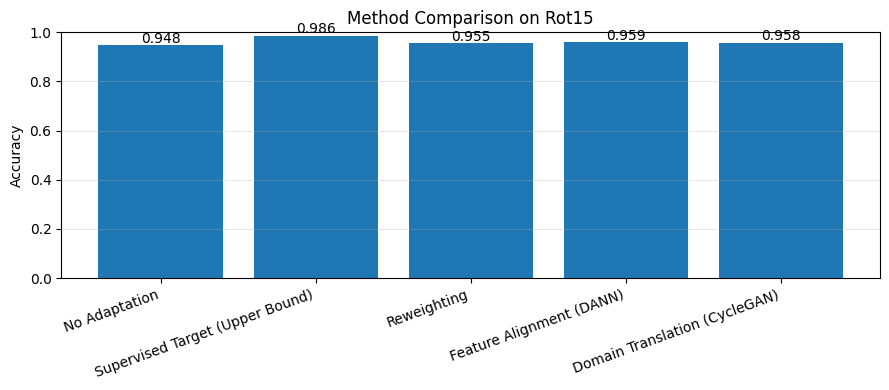

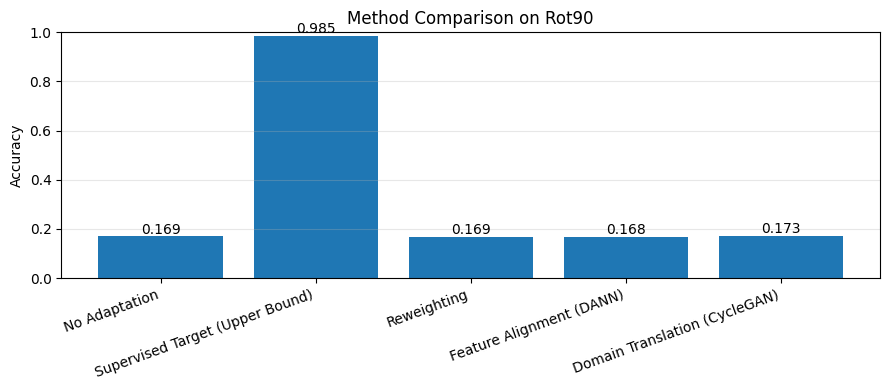

In [63]:
plot_method_comparison(summary_df, domains=("Rot15", "Rot90"))

# Per-class Improvements


=== Class Improvement | Reweighting | Rot15 ===


,Class,Before,After,Improvement
4,4,0.898167,0.947047,0.048880
7,7,0.875486,0.921206,0.045720
1,1,0.946256,0.970044,0.023789
8,8,0.980493,0.989733,0.009240
5,5,0.977578,0.986547,0.008969
0,0,0.988776,0.990816,0.002041
2,2,0.980620,0.974806,-0.005814
3,3,0.984158,0.969307,-0.014851
6,6,0.957203,0.936326,-0.020877
9,9,0.897919,0.867195,-0.030723


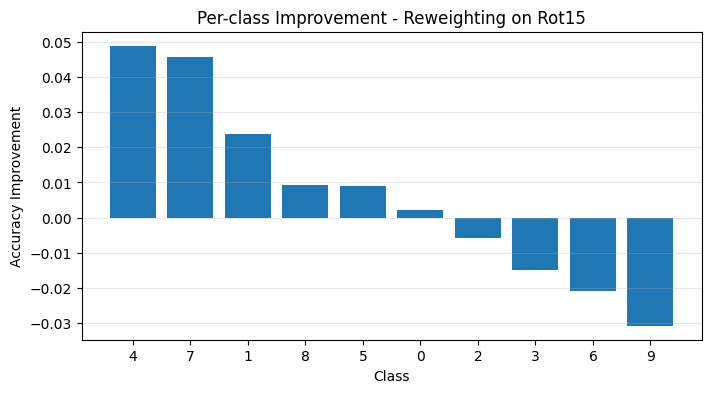


=== Class Improvement | Feature Alignment (DANN) | Rot15 ===


,Class,Before,After,Improvement
9,9,0.897919,0.931615,0.033697
1,1,0.946256,0.974449,0.028194
7,7,0.875486,0.897860,0.022374
4,4,0.898167,0.915479,0.017312
5,5,0.977578,0.982063,0.004484
6,6,0.957203,0.960334,0.003132
0,0,0.988776,0.991837,0.003061
2,2,0.980620,0.979651,-0.000969
8,8,0.980493,0.978439,-0.002053
3,3,0.984158,0.981188,-0.002970


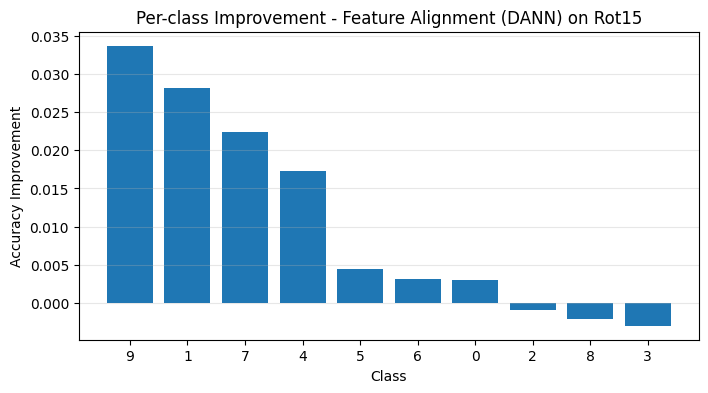


=== Class Improvement | Domain Translation (CycleGAN) | Rot15 ===


,Class,Before,After,Improvement
4,4,0.898167,0.948065,0.049898
9,9,0.897919,0.934589,0.036670
7,7,0.875486,0.900778,0.025292
6,6,0.957203,0.975992,0.018789
2,2,0.980620,0.983527,0.002907
3,3,0.984158,0.986139,0.001980
0,0,0.988776,0.989796,0.001020
8,8,0.980493,0.974333,-0.006160
1,1,0.946256,0.929515,-0.016740
5,5,0.977578,0.960762,-0.016816


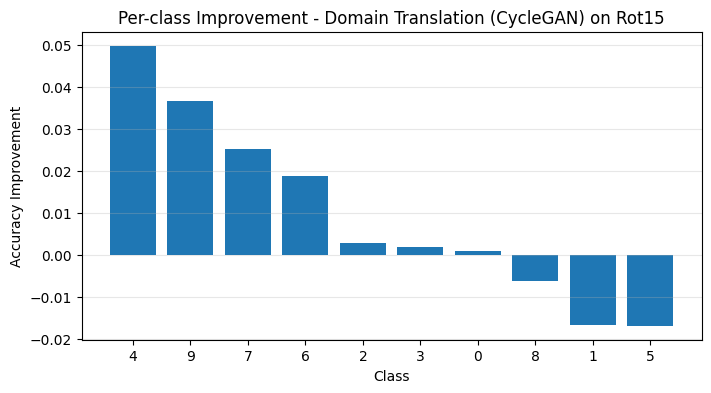


=== Class Improvement | Reweighting | Rot90 ===


,Class,Before,After,Improvement
7,7,0.016537,0.037938,0.021401
2,2,0.350775,0.368217,0.017442
0,0,0.817347,0.834694,0.017347
1,1,0.005286,0.005286,0.000000
9,9,0.030723,0.030723,0.000000
3,3,0.008911,0.007921,-0.000990
8,8,0.096509,0.095483,-0.001027
4,4,0.060081,0.050916,-0.009165
6,6,0.014614,0.002088,-0.012526
5,5,0.335202,0.295964,-0.039238


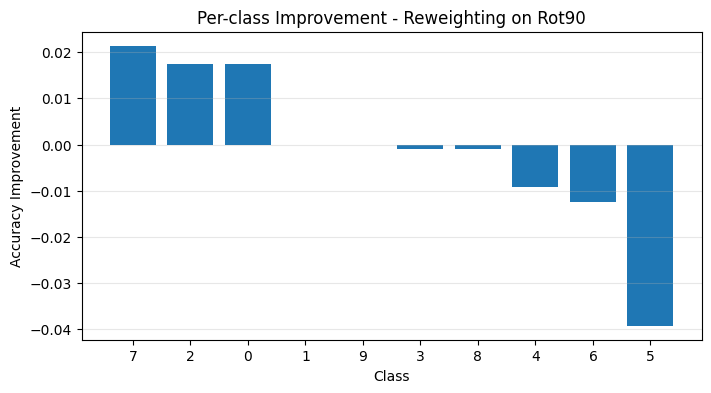


=== Class Improvement | Feature Alignment (DANN) | Rot90 ===


,Class,Before,After,Improvement
0,0,0.817347,0.884694,0.067347
7,7,0.016537,0.054475,0.037938
4,4,0.060081,0.085540,0.025458
1,1,0.005286,0.014978,0.009692
9,9,0.030723,0.032706,0.001982
3,3,0.008911,0.006931,-0.001980
6,6,0.014614,0.003132,-0.011482
8,8,0.096509,0.084189,-0.012320
2,2,0.350775,0.335271,-0.015504
5,5,0.335202,0.202915,-0.132287


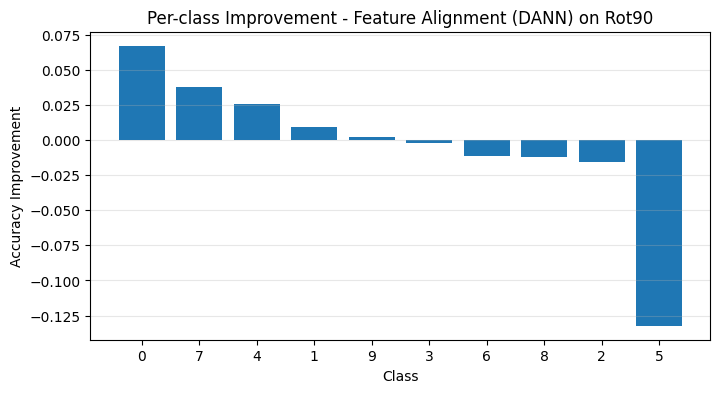


=== Class Improvement | Domain Translation (CycleGAN) | Rot90 ===


,Class,Before,After,Improvement
1,1,0.005286,0.230837,0.225551
8,8,0.096509,0.289528,0.193018
9,9,0.030723,0.198216,0.167493
3,3,0.008911,0.176238,0.167327
7,7,0.016537,0.131323,0.114786
6,6,0.014614,0.120042,0.105428
4,4,0.060081,0.063136,0.003055
2,2,0.350775,0.130814,-0.219961
5,5,0.335202,0.084081,-0.251121
0,0,0.817347,0.290816,-0.526531


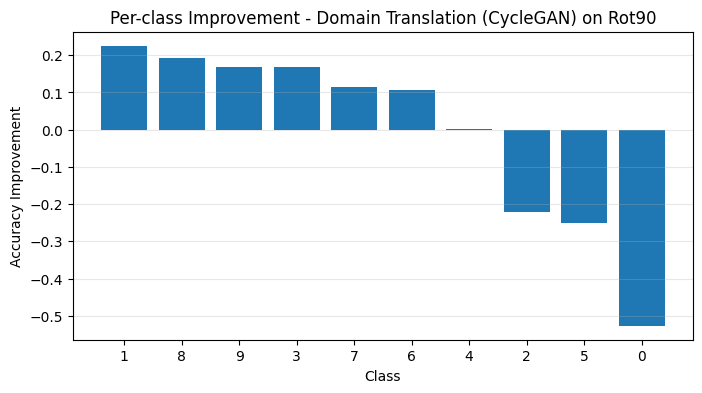

In [64]:
class_improvement(baseline_rot15, reweight15_target, "Reweighting", "Rot15")
class_improvement(baseline_rot15, dann15_target, "Feature Alignment (DANN)", "Rot15")
class_improvement(baseline_rot15, translation15_target, "Domain Translation (CycleGAN)", "Rot15")

class_improvement(baseline_rot90, reweight90_target, "Reweighting", "Rot90")
class_improvement(baseline_rot90, dann90_target, "Feature Alignment (DANN)", "Rot90")
class_improvement(baseline_rot90, translation90_target, "Domain Translation (CycleGAN)", "Rot90")

# Show sample images

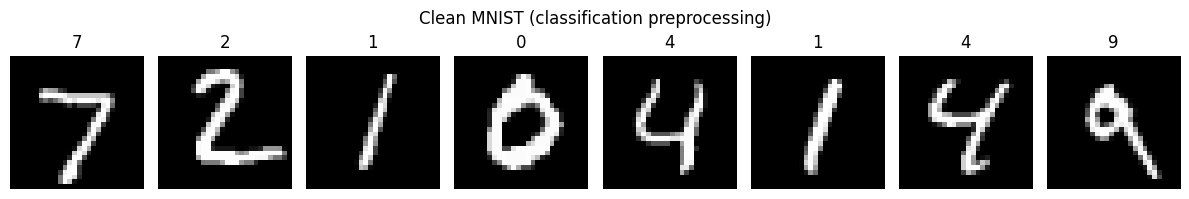

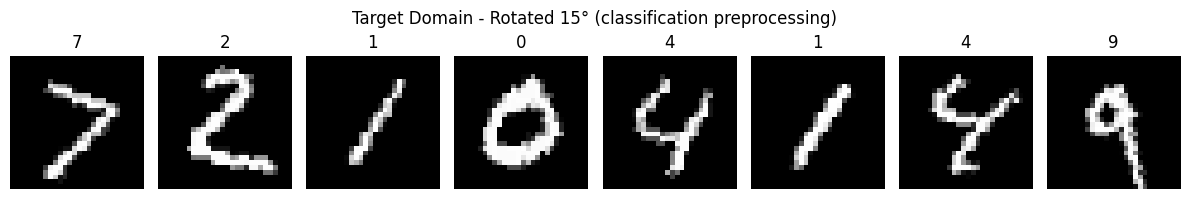

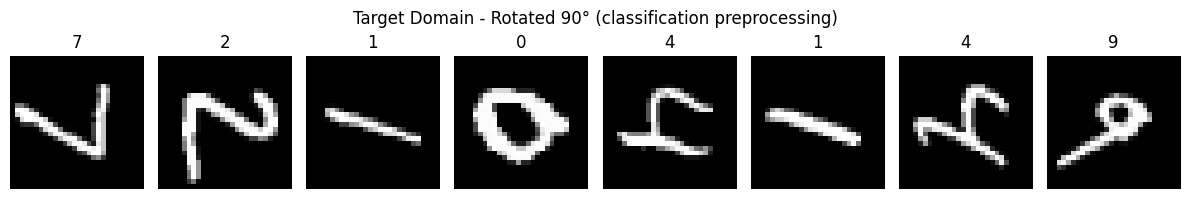

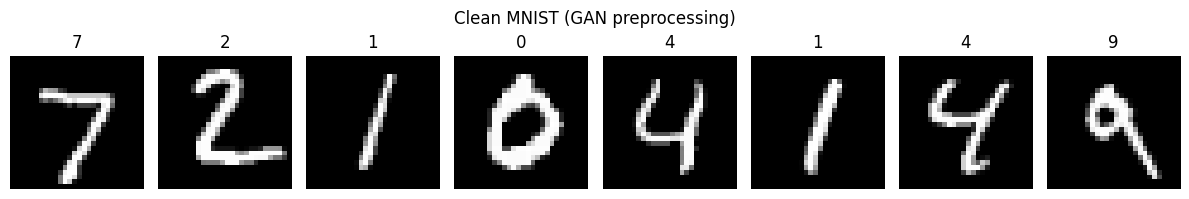

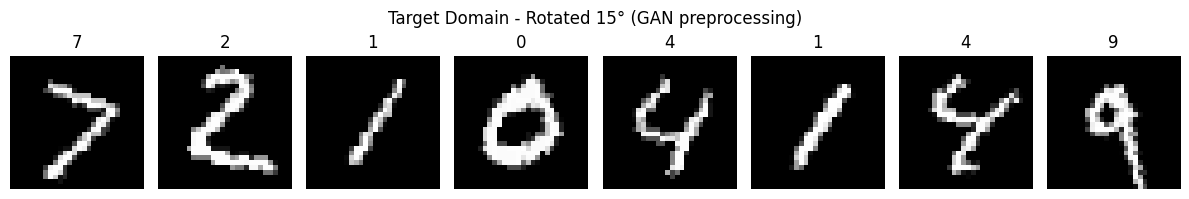

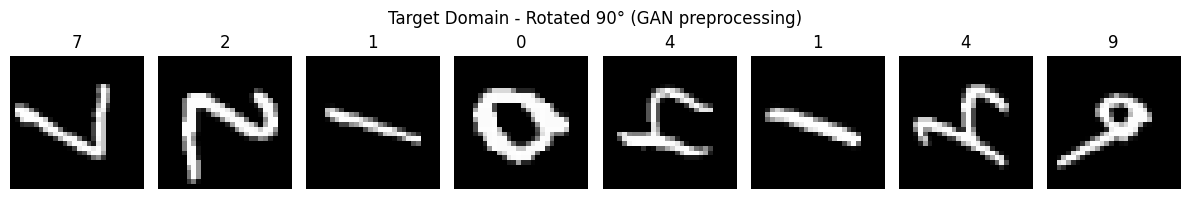

In [65]:
show_samples(source_test, n=8, title="Clean MNIST (classification preprocessing)")
show_samples(target15_test, n=8, title="Target Domain - Rotated 15° (classification preprocessing)")
show_samples(target90_test, n=8, title="Target Domain - Rotated 90° (classification preprocessing)")

show_samples(source_test_gan, n=8, title="Clean MNIST (GAN preprocessing)")
show_samples(target15_test_gan, n=8, title="Target Domain - Rotated 15° (GAN preprocessing)")
show_samples(target90_test_gan, n=8, title="Target Domain - Rotated 90° (GAN preprocessing)")